In [ ]:
""" The goal of this notebook is to setp by step develop Metadynamics code for ASE.
    It will be based on the biASE calculator
    
""" 

In [ ]:
from biASE import Direct_General_Bias_Calculator

In [ ]:
from ase.atoms import Atoms
from ase import units
from ase.io import read
import jax

from ase.md.langevin import Langevin
from ase.md.verlet import VelocityVerlet
from ase.md.velocitydistribution import MaxwellBoltzmannDistribution,Stationary, ZeroRotation
from ase.constraints import FixedPlane


import numpy as np
import matplotlib.pyplot as plt
from ase.calculators.calculator import Calculator, all_changes
from ase.io import Trajectory
import copy

from ase.calculators.mixing import LinearCombinationCalculator,MixedCalculator
import time
import jax.numpy as jnp


In [ ]:
"""Langevin dynamics class."""
from typing import IO, Optional, Union

import numpy as np

from ase import Atoms, units
from ase.md.md import MolecularDynamics
from ase.parallel import DummyMPI, world


class Langevin(MolecularDynamics):
    """Langevin (constant N, V, T) molecular dynamics."""

    # Helps Asap doing the right thing.  Increment when changing stuff:
    _lgv_version = 5

    def __init__(
        self,
        atoms: Atoms,
        timestep: float,
        temperature: Optional[float] = None,
        friction: Optional[float] = None,
        fixcm: bool = True,
        *,
        temperature_K: Optional[float] = None,
        trajectory: Optional[str] = None,
        logfile: Optional[Union[IO, str]] = None,
        loginterval: int = 1,
        communicator=world,
        rng=None,
        append_trajectory: bool = False,
    ):
        """
        Parameters:

        atoms: Atoms object
            The list of atoms.

        timestep: float
            The time step in ASE time units.

        temperature: float (deprecated)
            The desired temperature, in electron volt.

        temperature_K: float
            The desired temperature, in Kelvin.

        friction: float
            A friction coefficient in inverse ASE time units.
            For example, set ``0.01 / ase.units.fs`` to provide
            0.01 fs\\ :sup:`−1` (10 ps\\ :sup:`−1`).

        fixcm: bool (optional)
            If True, the position and momentum of the center of mass is
            kept unperturbed.  Default: True.

        rng: RNG object (optional)
            Random number generator, by default numpy.random.  Must have a
            standard_normal method matching the signature of
            numpy.random.standard_normal.

        logfile: file object or str (optional)
            If *logfile* is a string, a file with that name will be opened.
            Use '-' for stdout.

        trajectory: Trajectory object or str (optional)
            Attach trajectory object.  If *trajectory* is a string a
            Trajectory will be constructed.  Use *None* (the default) for no
            trajectory.

        communicator: MPI communicator (optional)
            Communicator used to distribute random numbers to all tasks.
            Default: ase.parallel.world. Set to None to disable communication.

        append_trajectory: bool (optional)
            Defaults to False, which causes the trajectory file to be
            overwritten each time the dynamics is restarted from scratch.
            If True, the new structures are appended to the trajectory
            file instead.

        The temperature and friction are normally scalars, but in principle one
        quantity per atom could be specified by giving an array.

        RATTLE constraints can be used with these propagators, see:
        E. V.-Eijnden, and G. Ciccotti, Chem. Phys. Lett. 429, 310 (2006)

        The propagator is Equation 23 (Eq. 39 if RATTLE constraints are used)
        of the above reference.  That reference also contains another
        propagator in Eq. 21/34; but that propagator is not quasi-symplectic
        and gives a systematic offset in the temperature at large time steps.
        """
        if friction is None:
            raise TypeError("Missing 'friction' argument.")
        self.fr = friction
        self.temp = units.kB * self._process_temperature(temperature,
                                                         temperature_K, 'eV')
        self.fix_com = fixcm
        if communicator is None:
            communicator = DummyMPI()
        self.communicator = communicator
        if rng is None:
            self.rng = np.random
        else:
            self.rng = rng
        MolecularDynamics.__init__(self, atoms, timestep, trajectory,
                                   logfile, loginterval,
                                   append_trajectory=append_trajectory)
        self.updatevars()

    def todict(self):
        d = MolecularDynamics.todict(self)
        d.update({'temperature_K': self.temp / units.kB,
                  'friction': self.fr,
                  'fixcm': self.fix_com})
        return d

    def set_temperature(self, temperature=None, temperature_K=None):
        self.temp = units.kB * self._process_temperature(temperature,
                                                         temperature_K, 'eV')
        self.updatevars()

    def set_friction(self, friction):
        self.fr = friction
        self.updatevars()

    def set_timestep(self, timestep):
        self.dt = timestep
        self.updatevars()

    def updatevars(self):
        dt = self.dt
        T = self.temp
        fr = self.fr
        masses = self.masses
        sigma = np.sqrt(2 * T * fr / masses)

        self.c1 = dt / 2. - dt * dt * fr / 8.
        self.c2 = dt * fr / 2 - dt * dt * fr * fr / 8.
        self.c3 = np.sqrt(dt) * sigma / 2. - dt**1.5 * fr * sigma / 8.
        self.c5 = dt**1.5 * sigma / (2 * np.sqrt(3))
        self.c4 = fr / 2. * self.c5

    def step(self, forces=None):
        atoms = self.atoms
        natoms = len(atoms)

        if forces is None:
            forces = atoms.get_forces(md=True)

        # This velocity as well as rnd_pos, rnd_mom and a few other
        # variables are stored as attributes, so Asap can do its magic
        # when atoms migrate between processors.
        self.v = atoms.get_velocities()

        xi = self.rng.standard_normal(size=(natoms, 3))
        eta = self.rng.standard_normal(size=(natoms, 3))

        # When holonomic constraints for rigid linear triatomic molecules are
        # present, ask the constraints to redistribute xi and eta within each
        # triple defined in the constraints. This is needed to achieve the
        # correct target temperature.
        for constraint in self.atoms.constraints:
            if hasattr(constraint, 'redistribute_forces_md'):
                constraint.redistribute_forces_md(atoms, xi, rand=True)
                constraint.redistribute_forces_md(atoms, eta, rand=True)

        self.communicator.broadcast(xi, 0)
        self.communicator.broadcast(eta, 0)

        # To keep the center of mass stationary, we have to calculate
        # the random perturbations to the positions and the momenta,
        # and make sure that they sum to zero.
        self.rnd_pos = self.c5 * eta
        self.rnd_vel = self.c3 * xi - self.c4 * eta
        if self.fix_com:
            self.rnd_pos -= self.rnd_pos.sum(axis=0) / natoms
            self.rnd_vel -= (self.rnd_vel *
                             self.masses).sum(axis=0) / (self.masses * natoms)

        # First halfstep in the velocity.
        self.v += (self.c1 * forces / self.masses - self.c2 * self.v +
                   self.rnd_vel)

        # Full step in positions
        x = atoms.get_positions()

        # Step: x^n -> x^(n+1) - this applies constraints if any.
        atoms.set_positions(x + self.dt * self.v + self.rnd_pos)

        # recalc velocities after RATTLE constraints are applied
        self.v = (self.atoms.get_positions() - x - self.rnd_pos) / self.dt
        forces = atoms.get_forces(md=True)

        # Update the velocities
        self.v += (self.c1 * forces / self.masses - self.c2 * self.v +
                   self.rnd_vel)

        # Second part of RATTLE taken care of here
        atoms.set_momenta(self.v * self.masses)
        print(self.nsteps, " Momeneta " ,self.v * self.masses)
        return forces

In [ ]:
"""Langevin dynamics class.""" #ASE-developers. Last updated on Tue, 08 Oct 2024 05:08:38.

import numpy as np

from ase.md.md import MolecularDynamics
from ase.parallel import world, DummyMPI
from ase import units


class Metadynamics(MolecularDynamics):
    """Langevin (constant N, V, T) molecular dynamics."""

    # Helps Asap doing the right thing.  Increment when changing stuff:
    _lgv_version = 4

    def __init__(self, atoms, timestep, temperature=None, friction=None,
                 fixcm=True, *, temperature_K=None, trajectory=None,
                 logfile=None, loginterval=1, communicator=world,output_file = None,
                 rng=None, append_trajectory=False,meta_dyn=True,cv_function = None,
                 cv_constants=(None,), std_dev=0.1,bias_height = 0.001, interval_size = 10):
        """
        Parameters:

        atoms: Atoms object
            The list of atoms.

        timestep: float
            The time step in ASE time units.

        temperature: float (deprecated)
            The desired temperature, in electron volt.

        temperature_K: float
            The desired temperature, in Kelvin.

        friction: float
            A friction coefficient in inverse ASE time units.
            For example, set ``0.01 / ase.units.fs`` to provide
            0.01 fs\\ :sup:`−1` (10 ps\\ :sup:`−1`).

        fixcm: bool (optional)
            If True, the position and momentum of the center of mass is
            kept unperturbed.  Default: True.

        rng: RNG object (optional)
            Random number generator, by default numpy.random.  Must have a
            standard_normal method matching the signature of
            numpy.random.standard_normal.

        logfile: file object or str (optional)
            If *logfile* is a string, a file with that name will be opened.
            Use '-' for stdout.

        trajectory: Trajectory object or str (optional)
            Attach trajectory object.  If *trajectory* is a string a
            Trajectory will be constructed.  Use *None* (the default) for no
            trajectory.

        communicator: MPI communicator (optional)
            Communicator used to distribute random numbers to all tasks.
            Default: ase.parallel.world. Set to None to disable communication.

        append_trajectory: bool (optional)
            Defaults to False, which causes the trajectory file to be
            overwritten each time the dynamics is restarted from scratch.
            If True, the new structures are appended to the trajectory
            file instead.

        The temperature and friction are normally scalars, but in principle one
        quantity per atom could be specified by giving an array.

        RATTLE constraints can be used with these propagators, see:
        E. V.-Eijnden, and G. Ciccotti, Chem. Phys. Lett. 429, 310 (2006)

        The propagator is Equation 23 (Eq. 39 if RATTLE constraints are used)
        of the above reference.  That reference also contains another
        propagator in Eq. 21/34; but that propagator is not quasi-symplectic
        and gives a systematic offset in the temperature at large time steps.
        """
        if friction is None:
            raise TypeError("Missing 'friction' argument.")
        self.fr = friction
        self.temp = units.kB * self._process_temperature(temperature,
                                                         temperature_K, 'eV')
        self.fix_com = fixcm
        if communicator is None:
            communicator = DummyMPI()
        self.communicator = communicator
        if rng is None:
            self.rng = np.random
        else:
            self.rng = rng
        MolecularDynamics.__init__(self, atoms, timestep, trajectory,
                                   logfile, loginterval,
                                   append_trajectory=append_trajectory)
        self.updatevars()
        
        ### Added from med
        self.old_means= None
        print("Initial Array:",self.old_means, atoms.get_positions().shape)
        self.meta_dyn = meta_dyn
        if meta_dyn ==True and cv_function==None:
             raise TypeError("Please provide cvs  if you want to use the Metadynamics option (meta_dyn)!")
        else:
            self.cvs = cv_function
            self.len_cvs = len(list(self.cvs(atoms.get_positions())))
            self.cv_constants=cv_constants
        self.std_dev =std_dev
        self.main_potential = atoms.get_calculator()
        self.bias_height= bias_height
        self.interval_size = interval_size
        self.output_file = output_file
        self.timestep = timestep
        header = f"\t \t\t\t \t time \t \t CV1 \t \t CV2 \t \t \t std1   \t std2 \t height \t biasfactor \n"
        if self.output_file != None:
            with open(self.output_file, "w") as file:
                file.write(header)
        
    def todict(self):
        d = MolecularDynamics.todict(self)
        d.update({'temperature_K': self.temp / units.kB,
                  'friction': self.fr,
                  'fixcm': self.fix_com})
        return d

    def set_temperature(self, temperature=None, temperature_K=None):
        self.temp = units.kB * self._process_temperature(temperature,
                                                         temperature_K, 'eV')
        self.updatevars()

    def set_friction(self, friction):
        self.fr = friction
        self.updatevars()

    def set_timestep(self, timestep):
        self.dt = timestep
        self.updatevars()

    def updatevars(self):
        dt = self.dt
        T = self.temp
        fr = self.fr
        masses = self.masses
        sigma = np.sqrt(2 * T * fr / masses)

        self.c1 = dt / 2. - dt * dt * fr / 8.
        self.c2 = dt * fr / 2 - dt * dt * fr * fr / 8.
        self.c3 = np.sqrt(dt) * sigma / 2. - dt**1.5 * fr * sigma / 8.
        self.c5 = dt**1.5 * sigma / (2 * np.sqrt(3))
        self.c4 = fr / 2. * self.c5

    def step(self, forces=None):
        atoms = self.atoms
        natoms = len(atoms)
        #print(self.nsteps)
        #print(self.nsteps)
        if self.nsteps>1: # one could ask why is the update of the calc here?
            if self.meta_dyn == True:                # This is a great question! The reason is that when
                #print(self.nsteps, 'update the calc')# The calc gets updated all saved forces and energies get lost!
                atoms.calc =self.meta_dyn_calc       # So updating the calc in the step it self do not make sense
        
        if forces is None:
            forces = atoms.get_forces(md=True)

        # This velocity as well as rnd_pos, rnd_mom and a few other
        # variables are stored as attributes, so Asap can do its magic
        # when atoms migrate between processors.
        self.v = atoms.get_velocities()

        xi = self.rng.standard_normal(size=(natoms, 3))
        eta = self.rng.standard_normal(size=(natoms, 3))

        # When holonomic constraints for rigid linear triatomic molecules are
        # present, ask the constraints to redistribute xi and eta within each
        # triple defined in the constraints. This is needed to achieve the
        # correct target temperature.
        for constraint in self.atoms.constraints:
            if hasattr(constraint, 'redistribute_forces_md'):
                constraint.redistribute_forces_md(atoms, xi, rand=True)
                constraint.redistribute_forces_md(atoms, eta, rand=True)

        self.communicator.broadcast(xi, 0)
        self.communicator.broadcast(eta, 0)

        # To keep the center of mass stationary, we have to calculate
        # the random perturbations to the positions and the momenta,
        # and make sure that they sum to zero.
        self.rnd_pos = self.c5 * eta
        self.rnd_vel = self.c3 * xi - self.c4 * eta
        if self.fix_com:
            self.rnd_pos -= self.rnd_pos.sum(axis=0) / natoms
            self.rnd_vel -= (self.rnd_vel *
                             self.masses).sum(axis=0) / (self.masses * natoms)

        # First halfstep in the velocity.
        self.v += (self.c1 * forces / self.masses - self.c2 * self.v +
                   self.rnd_vel)

        # Full step in positions
        x = atoms.get_positions()

        # Step: x^n -> x^(n+1) - this applies constraints if any.
        atoms.set_positions(x + self.dt * self.v + self.rnd_pos)

        # recalc velocities after RATTLE constraints are applied
        self.v = (self.atoms.get_positions() - x - self.rnd_pos) / self.dt
        forces = atoms.get_forces(md=True)

        # Update the velocities
        self.v += (self.c1 * forces / self.masses - self.c2 * self.v +
                   self.rnd_vel)

        # Second part of RATTLE taken care of here
        atoms.set_momenta(self.v * self.masses)
        #start = time.time()
        print(self.nsteps, " Forces before: ",forces)
        ### We update here the potenial if wanted!
        if self.nsteps % self.interval_size ==0:
            if self.meta_dyn == True:
                self.current_cvs = self.cvs(atoms.get_positions())
                print(self.nsteps," Old Means: ",self.old_means, " New Mean: ", self.current_cvs)
                if self.old_means is None:
                    self.old_means = np.array([self.current_cvs]) # save only cv instead of position!!!
                else:
                    self.old_means = np.vstack([self.old_means, self.current_cvs]) # save only cv instead of position!!!

                if self.nsteps<self.interval_size:
                    self.bias_potential = self.bias_setup(*self.cv_constants)
                else:
                    print(self.nsteps, " Update Bias")
                    self.bias_update()
                    
                #print(self.old_means)
                self.meta_dyn_calc = LinearCombinationCalculator([self.main_potential,self.bias_potential],[1.,1.])
                #end = time.time()
                #print(end-start)
                #print(self.nsteps)
                if self.output_file != None:
                        with open(self.output_file, "+a") as file:
                            if self.len_cvs ==1:
                                file.write(f'\t\t\t\t \t{self.nsteps*self.timestep}\t{self.current_cvs[0]}\t{self.std_dev}\t{self.bias_height}\t{"Not_WT"}\n')
                            else:
                                file.write(f'\t\t\t\t \t{self.nsteps*self.timestep}\t{self.current_cvs[0]}\t{self.current_cvs[1]}\t{self.std_dev}\t{self.std_dev}\t{self.bias_height}\t{"Not_WT"}\n')
                            file.close
                            
        if self.nsteps > 1 and self.nsteps <100:
            print(self.nsteps, " Momeneta " ,self.v * self.masses)
            print(self.nsteps, " Forces after: ",forces)
            true_calc=atoms.get_calculator()
            atoms.calc= self.bias_potential
            f_b=atoms.get_forces()
            print("Forces bias: ", f_b)
            atoms.calc= self.main_potential
            print("Main Potential: ",self.main_potential)
            f_m=atoms.get_forces()
            print("Forces potential: ", f_m)
            atoms.calc=true_calc
        return forces

    def bias_setup(self,*args):
        """Here the bias along the cv will be build
           ATM only one cvs with a one dimensional gaussian will be supported
        
        """
        if self.len_cvs ==1 :
            if self.cv_constants==(None,):
                print(self.nsteps, "new bias calc")
                self.gaussian_bias = Direct_General_Bias_Calculator(self.gaussian_1D,use_jit=True)
            else:
                print(self.nsteps, "new bias calc")
                self.gaussian_bias = Direct_General_Bias_Calculator(self.gaussian_1D,*args,use_jit=True)
        elif self.len_cvs ==2:
            if self.cv_constants==(None,):
                self.gaussian_bias = Direct_General_Bias_Calculator(self.gaussian_2D,use_jit=True)
            else:
                self.gaussian_bias = Direct_General_Bias_Calculator(self.gaussian_2D,*args,use_jit=True)
            
        else:
            raise TypeError("CVs need to be inform of an array with one or two entrys! e.g. jnp.array([cv1,cv2]).")
            
        return self.gaussian_bias
    
    def bias_update(self):
        if self.len_cvs ==1 :
            self.bias_potential.update_function(self.gaussian_1D)
        if self.len_cvs ==2 :
            self.bias_potential.update_function(self.gaussian_2D)

    def gaussian_1D(self,positions,*args): ### here with jax numpy
        """ 
        x (float or numpy array): Input value(s) for evaluating the Gaussian.
            mean (float or numpy array): Mean(s) of the Gaussian(s).
            std_dev (float): Standard deviation of the Gaussian(s).

        Returns:
            float or numpy array: Value(s) of the Gaussian(s) at the given input(s), summed over all means.
            
            
            this function needs to be tested! seems to be the same as the above numpy version but forces need to be tested
        """ 
        cvs=self.cvs(positions,*args)
        x = cvs[0]
        mean_cvs = self.old_means.flatten()
        jax.debug.print("mean of the gaussian_1D: {}", mean_cvs) 
        std_dev = self.std_dev

        # Evaluate the Gaussian for all means at once using numpy broadcasting
        gaussian_vals = jnp.exp(-0.5*((x - mean_cvs[:, jnp.newaxis])**2/(0.5*std_dev**2))) 
        
        # Sum over all means and return the result
        #print(jnp.sum(gaussian_vals, axis=0)[0])
        return self.bias_height*jnp.sum(gaussian_vals, axis=0)[0] # why [0] check that more - is necessay bc out put would be a 1D list with one entrence
    
    
    def gaussian_2D(self,positions,*args):
        """
        Evaluate a 2D Gaussian potential energy surface for the given input collective variable(s) (cvs).

        Args:
            cvs (float or numpy array): Input value(s) for evaluating the 2D Gaussian.

        Returns:
            float or numpy array: Value(s) of the 2D Gaussian at the given input(s), summed over all means.
        """
        cvs=self.cvs(positions,*args)
        x, y = cvs
        mean_cvs= self.old_means
        
        std_dev = self.std_dev
        
        #print(mean_cvs[:, 0])
        # Evaluate the Gaussian for all means at once using numpy broadcasting
        gaussian_vals = jnp.exp(-0.5*((x - mean_cvs[:, 0])**2/(0.5*std_dev**2)) \
                                                      - 0.5*((y - mean_cvs[:, 1])**2/(0.5*std_dev**2)))

        # Sum over all means and return the result
        #print(jnp.sum(gaussian_vals, axis=0)[0])
        e = self.bias_height*jnp.sum(gaussian_vals,axis=0)#[0] 
        #jax.debug.print("mean of the gaussian_2D: {}", mean_cvs) 
        #jax.debug.print("The energy of the gaussian_2D: {}", e) 
        return e #self.bias_height*jnp.sum(gaussian_vals,axis=0)#[0] 


    def return_bias(self):
        return self.bias_potential 

    
    def return_biased_potential(self):
        return self.meta_dyn_calc

In [ ]:
"""Langevin dynamics class.""" #copyed from the v3.22.1 not the master!

import numpy as np

from ase.md.md import MolecularDynamics
from ase.parallel import world, DummyMPI
from ase import units


class WT_Metadynamics(MolecularDynamics):
    """Well_tempered Metadynmaics with Langevin (constant N, V, T) molecular dynamics."""

    # Helps Asap doing the right thing.  Increment when changing stuff:
    _lgv_version = 4

    def __init__(self, atoms, timestep, temperature=None, friction=None,
                 fixcm=True, *, temperature_K=None, trajectory=None,
                 logfile=None, loginterval=1, communicator=world,
                 rng=None, append_trajectory=False,meta_dyn=True,cv_function = None,
                 cv_constants=(None,), std_dev=0.1, bias_height=0.001, interval_size = 10,
                 bias_factor=5, output_file = None,well_temp):
        """
        Parameters:

        atoms: Atoms object
            The list of atoms.

        timestep: float
            The time step in ASE time units.

        temperature: float (deprecated)
            The desired temperature, in electron volt.

        temperature_K: float
            The desired temperature, in Kelvin.

        friction: float
            A friction coefficient, typically 1e-4 to 1e-2.

        fixcm: bool (optional)
            If True, the position and momentum of the center of mass is
            kept unperturbed.  Default: True.

        rng: RNG object (optional)
            Random number generator, by default numpy.random.  Must have a
            standard_normal method matching the signature of
            numpy.random.standard_normal.

        logfile: file object or str (optional)
            If *logfile* is a string, a file with that name will be opened.
            Use '-' for stdout.

        trajectory: Trajectory object or str (optional)
            Attach trajectory object.  If *trajectory* is a string a
            Trajectory will be constructed.  Use *None* (the default) for no
            trajectory.

        communicator: MPI communicator (optional)
            Communicator used to distribute random numbers to all tasks.
            Default: ase.parallel.world. Set to None to disable communication.

        append_trajectory: bool (optional)
            Defaults to False, which causes the trajectory file to be
            overwritten each time the dynamics is restarted from scratch.
            If True, the new structures are appended to the trajectory
            file instead.

        The temperature and friction are normally scalars, but in principle one
        quantity per atom could be specified by giving an array.

        RATTLE constraints can be used with these propagators, see:
        E. V.-Eijnden, and G. Ciccotti, Chem. Phys. Lett. 429, 310 (2006)

        The propagator is Equation 23 (Eq. 39 if RATTLE constraints are used)
        of the above reference.  That reference also contains another
        propagator in Eq. 21/34; but that propagator is not quasi-symplectic
        and gives a systematic offset in the temperature at large time steps.
        """
        if friction is None:
            raise TypeError("Missing 'friction' argument.")
        self.fr = friction
        self.temp = units.kB * self._process_temperature(temperature,
                                                         temperature_K, 'eV')
        self.fix_com = fixcm
        if communicator is None:
            communicator = DummyMPI()
        self.communicator = communicator
        if rng is None:
            self.rng = np.random
        else:
            self.rng = rng
        MolecularDynamics.__init__(self, atoms, timestep, trajectory,
                                   logfile, loginterval,
                                   append_trajectory=append_trajectory)
        self.updatevars()
        
        ### Added from med
        self.old_means= None
        print("Initial Array:",self.old_means, atoms.get_positions().shape)
        self.meta_dyn = meta_dyn
        if meta_dyn ==True and cv_function==None:
             raise TypeError("Please provide cvs  if you want to use the Metadynamics option (meta_dyn)!")
        else:
            self.cvs = cv_function
            self.len_cvs = len(list(self.cvs(atoms.get_positions())))
            self.cv_constants=cv_constants
        self.std_dev =std_dev
        self.main_potential = atoms.get_calculator()
        self.bias_height= bias_height
        self.interval_size = interval_size
        self.bias_factor = bias_factor
        self.output_file = output_file
        self.timestep = timestep
        self.well_temp=well_temp
    
        header = f"\t \t\t\t \t time \t \t CV1 \t \t CV2 \t \t \t std1   \t std2 \t height \t biasfactor \n"
        if self.output_file != None:
            with open(self.output_file, "w") as file:
                file.write(header)
        
    def todict(self):
        d = MolecularDynamics.todict(self)
        d.update({'temperature_K': self.temp / units.kB,
                  'friction': self.fr,
                  'fixcm': self.fix_com})
        return d

    def set_temperature(self, temperature=None, temperature_K=None):
        self.temp = units.kB * self._process_temperature(temperature,
                                                         temperature_K, 'eV')
        self.updatevars()

    def set_friction(self, friction):
        self.fr = friction
        self.updatevars()

    def set_timestep(self, timestep):
        self.dt = timestep
        self.updatevars()

    def updatevars(self):
        dt = self.dt
        T = self.temp
        fr = self.fr
        masses = self.masses
        sigma = np.sqrt(2 * T * fr / masses)

        self.c1 = dt / 2. - dt * dt * fr / 8.
        self.c2 = dt * fr / 2 - dt * dt * fr * fr / 8.
        self.c3 = np.sqrt(dt) * sigma / 2. - dt**1.5 * fr * sigma / 8.
        self.c5 = dt**1.5 * sigma / (2 * np.sqrt(3))
        self.c4 = fr / 2. * self.c5

    def step(self, forces=None):
        print(self.nsteps)
        if (self.nsteps-1) % self.interval_size ==0: # one could ask why is the update of the calc here?
            if self.meta_dyn == True:                # This is a great question! The reason is that when
                #print(self.nsteps, 'update the calc')# The calc gets updated all saved forces and energies get lost!
                self.atoms.calc =self.meta_dyn_calc  #So updating the calc in the step it self do not make sense

                
        atoms = self.atoms
        natoms = len(atoms)
         
        #print(atoms.get_potential_energy(),self.atoms.get_potential_energy())
        
        if forces is None:
            forces = atoms.get_forces(md=True)
            #if (self.nsteps-1) % self.interval_size ==0:
                

        # This velocity as well as xi, eta and a few other variables are stored
        # as attributes, so Asap can do its magic when atoms migrate between
        # processors.
        self.v = atoms.get_velocities()

        self.xi = self.rng.standard_normal(size=(natoms, 3))
        self.eta = self.rng.standard_normal(size=(natoms, 3))

        # When holonomic constraints for rigid linear triatomic molecules are
        # present, ask the constraints to redistribute xi and eta within each
        # triple defined in the constraints. This is needed to achieve the
        # correct target temperature.
        for constraint in self.atoms.constraints:
            if hasattr(constraint, 'redistribute_forces_md'):
                constraint.redistribute_forces_md(atoms, self.xi, rand=True)
                constraint.redistribute_forces_md(atoms, self.eta, rand=True)

        self.communicator.broadcast(self.xi, 0)
        self.communicator.broadcast(self.eta, 0)

        # First halfstep in the velocity.
        self.v += (self.c1 * forces / self.masses - self.c2 * self.v +
                   self.c3 * self.xi - self.c4 * self.eta)

        # Full step in positions
        x = atoms.get_positions()
        if self.fix_com:
            old_com = atoms.get_center_of_mass()
        # Step: x^n -> x^(n+1) - this applies constraints if any.
        atoms.set_positions(x + self.dt * self.v + self.c5 * self.eta)
        if self.fix_com:
            atoms.set_center_of_mass(old_com)

        # recalc velocities after RATTLE constraints are applied
        self.v = (self.atoms.get_positions() - x -
                  self.c5 * self.eta) / self.dt
        forces = atoms.get_forces(md=True)

        # Update the velocities
        self.v += (self.c1 * forces / self.masses - self.c2 * self.v +
                   self.c3 * self.xi - self.c4 * self.eta)

        if self.fix_com:  # subtract center of mass vel
            self.v -= self._get_com_velocity(self.v)

        # Second part of RATTLE taken care of here
        atoms.set_momenta(self.v * self.masses)
        #start = time.time()
        ### We update here the potenial if wanted!
        if self.nsteps % self.interval_size ==0:
            if self.meta_dyn == True:
                self.current_pos = atoms.get_positions()
                self.current_cvs = self.cvs(self.current_pos)
                if self.old_means is None:
                    self.old_means = np.array([self.cvs(atoms.get_positions())]) # save only cv instead of position!!!
                    self.previous_portential = 0
                    self.regulation_factor=np.asarray([[np.exp(-self.previous_portential/(self.well_temp*self.bias_factor))]]) #insted pf self.temp regulation_factor=jnp.exp(-self.previous_portential/(self.temp*self.bias_factor)) # kB is already included here but what do to if given in K? 
                    print(self.previous_portential)
                else:
                    #print(self.temp,self.well_temp)
                    if self.len_cvs ==1:
                        self.previous_portential = self.gaussian_1D(self.current_pos)# was current_cvs = self.cvs(atoms.get_positions())
                        #print(self.previous_portential)
                    if self.len_cvs ==2:    
                        self.previous_portential = self.gaussian_2D(self.current_pos) # was current_cvs = self.cvs(atoms.get_positions())
                    self.regulation_factor=np.vstack([self.regulation_factor, np.exp(-self.previous_portential/(self.well_temp*self.bias_factor))] ) #instead of self.temp
                    #print(self.previous_portential,self.regulation_factor[-1])
                    #print("Old Means: ",self.position_array, " New Mean: ", self.cvs(atoms.get_positions()))
                    self.old_means = np.vstack([self.old_means, self.current_cvs]) # save only cv instead of position!!! # was current_cvs = self.cvs(atoms.get_positions())
                    #print(self.position_array)

                #print(self.regulation_factor)
                self.bias_potential = self.bias_setup(*self.cv_constants)
                
                #print(self.position_array)
                self.meta_dyn_calc = LinearCombinationCalculator([self.main_potential,self.bias_potential],[1.,1.])
                #end = time.time()
                #print(self.nsteps, 'set up the calc')
                #print(end-start)
                #print(self.nsteps)
                if self.output_file != None:
                        with open(self.output_file, "+a") as file:
                            if self.len_cvs ==1:
                                file.write(f'\t\t\t\t \t{self.nsteps*self.timestep}\t{self.current_cvs[0]}\t{self.std_dev}\t{self.bias_height*self.regulation_factor[-1][0]}\t{self.bias_factor}\n')
                            else:
                                file.write(f'\t\t\t\t \t{self.nsteps*self.timestep}\t{self.current_cvs[0]}\t{self.current_cvs[1]}\t{self.std_dev}\t{self.std_dev}\t{self.bias_height*self.regulation_factor[-1][0]}\t{self.bias_factor}\n')
                            file.close
                    #\t{self.current_cvs[1]}\t{self.std_dev}
                
        return forces

    def bias_setup(self,*args):
        """Here the bias along the cv will be build
           ATM only one cvs with a one dimensional gaussian will be supported
        
        """
        if self.len_cvs ==1 :
            if self.cv_constants==(None,):
                self.gaussian_bias = Direct_General_Bias_Calculator(self.gaussian_1D,use_jit=True)
            else:
                self.gaussian_bias = Direct_General_Bias_Calculator(self.gaussian_1D,*args,use_jit=True)
        elif self.len_cvs ==2:
            if self.cv_constants==(None,):
                self.gaussian_bias = Direct_General_Bias_Calculator(self.gaussian_2D,use_jit=True)
            else:
                self.gaussian_bias = Direct_General_Bias_Calculator(self.gaussian_2D,*args,use_jit=True)
            
        else:
            raise TypeError("CVs need to be inform of an array with one or two entrys! e.g. jnp.array([cv1,cv2]).")
            
        return self.gaussian_bias
    

    def gaussian_1D_sing_reg(self,cvs): ### here with jax numpy
        """ 
        x (float or numpy array): Input value(s) for evaluating the Gaussian.
            mean (float or numpy array): Mean(s) of the Gaussian(s).
            std_dev (float): Standard deviation of the Gaussian(s).

        Returns:
            float or numpy array: Value(s) of the Gaussian(s) at the given input(s), summed over all means.
            
            
            this function needs to be tested! seems to be the same as the above numpy version but forces need to be tested
        """ 
        x = cvs[0]
        mean_cvs = self.old_means.flatten()
        std_dev = self.std_dev

        # Evaluate the Gaussian for all means at once using numpy broadcasting
        gaussian_vals = jnp.exp(-0.5*((x - mean_cvs[:, jnp.newaxis])**2/(0.5*std_dev**2))) 
        
        #print('regulation_factor: ', self.previous_portential,self.nsteps)
        # Sum over all means and return the result
        #print(jnp.sum(gaussian_vals, axis=0)[0])
        #print('Previous Potential: ',  self.bias_height*self.regulation_factor*jnp.sum(gaussian_vals, axis=0)[0],self.nsteps)
        return self.bias_height*self.regulation_factor*jnp.sum(gaussian_vals, axis=0)[0] # why [0] check that more - is necessay bc out put would be a 1D list with one entrence
    
    def gaussian_1D(self,positions,*args): ### here with jax numpy
        """ 
        x (float or numpy array): Input value(s) for evaluating the Gaussian.
            mean (float or numpy array): Mean(s) of the Gaussian(s).
            std_dev (float): Standard deviation of the Gaussian(s).

        Returns:
            float or numpy array: Value(s) of the Gaussian(s) at the given input(s), summed over all means.
            
            
            this function needs to be tested! seems to be the same as the above numpy version but forces need to be tested
        """ 
        cvs=self.cvs(positions,*args)
        x = cvs[0]
        mean_cvs = self.old_means.flatten()
        std_dev = self.std_dev

        # Evaluate the Gaussian for all means at once using numpy broadcasting
        gaussian_vals = jnp.exp(-0.5*((x - mean_cvs[:, jnp.newaxis])**2/(0.5*std_dev**2))) 
        
        #print('regulation_factor: ', self.previous_portential,self.nsteps)
        # Sum over all means and return the result
        #print(jnp.sum(gaussian_vals, axis=0)[0])
        #print('Previous Potential: ',  self.bias_height*self.regulation_factor*jnp.sum(gaussian_vals, axis=0)[0],self.nsteps)
        return self.bias_height*jnp.sum(gaussian_vals*self.regulation_factor, axis=0)[0] # why [0] check that more - is necessay bc out put would be a 1D list with one entrence
    
    
    def gaussian_2D(self,positions,*args):
        """
        Evaluate a 2D Gaussian potential energy surface for the given input collective variable(s) (cvs).

        Args:
            cvs (float or numpy array): Input value(s) for evaluating the 2D Gaussian.

        Returns:
            float or numpy array: Value(s) of the 2D Gaussian at the given input(s), summed over all means.
        """
        cvs=self.cvs(positions,*args)
        x, y = cvs
        mean_cvs= self.old_means
        std_dev = self.std_dev
        
        #print(mean_cvs[:, 0])
        # Evaluate the Gaussian for all means at once using numpy broadcasting
        gaussian_vals = jnp.exp(-0.5*((x - mean_cvs[:, 0])**2/(0.5*std_dev**2)) \
                                                      - 0.5*((y - mean_cvs[:, 1])**2/(0.5*std_dev**2)))
        #regulation_factor=jnp.exp(-self.previous_portential/(self.temp*self.bias_factor)) #the kB here is used to transform from K to eV!
        #print('regulation_factor: ', self.previous_portential,self.nsteps)
        #print(mean_cvs,cvs)
        # Sum over all means and return the result
        #print(jnp.sum(gaussian_vals, axis=0)[0])
        
        '''print('Potential_NOW: ', self.bias_height*regulation_factor*jnp.sum(gaussian_vals,axis=0),self.nsteps)
        print('Sum_Gaussian:', jnp.sum(gaussian_vals,axis=0), 'Previous Potential: ', self.previous_portential,self.nsteps)
        print('Reg_factor: ',regulation_factor, 'T: ', self.temp)'''
        #print('HI')
        #print(self.regulation_factor)
        return self.bias_height*jnp.sum(gaussian_vals*self.regulation_factor,axis=0)[0] 

def gaussian_2D_sing(self,cvs):
        """
        Evaluate a 2D Gaussian potential energy surface for the given input collective variable(s) (cvs).

        Args:
            cvs (float or numpy array): Input value(s) for evaluating the 2D Gaussian.

        Returns:
            float or numpy array: Value(s) of the 2D Gaussian at the given input(s), summed over all means.
        """
        x, y = cvs
        mean_cvs= self.old_means
        std_dev = self.std_dev
        
        #print(mean_cvs[:, 0])
        # Evaluate the Gaussian for all means at once using numpy broadcasting
        gaussian_vals = jnp.exp(-0.5*((x - mean_cvs[:, 0])**2/(0.5*std_dev**2)) \
                                                      - 0.5*((y - mean_cvs[:, 1])**2/(0.5*std_dev**2)))
        #regulation_factor=jnp.exp(-self.previous_portential/(self.temp*self.bias_factor)) #the kB here is used to transform from K to eV!
        #print('regulation_factor: ', self.previous_portential,self.nsteps)
        #print(mean_cvs,cvs)
        # Sum over all means and return the result
        #print(jnp.sum(gaussian_vals, axis=0)[0])
        
        '''print('Potential_NOW: ', self.bias_height*regulation_factor*jnp.sum(gaussian_vals,axis=0),self.nsteps)
        print('Sum_Gaussian:', jnp.sum(gaussian_vals,axis=0), 'Previous Potential: ', self.previous_portential,self.nsteps)
        print('Reg_factor: ',regulation_factor, 'T: ', self.temp)'''
        #print('HI')
        return self.bias_height*self.regulation_factor*jnp.sum(gaussian_vals,axis=0)#[0] 
def return_bias(self):
    return self.bias_potential

def return_biased_potential(self):
    return self.meta_dyn_calc
def return_func(self):
    return self.old_means, self.regulation_factor

In [ ]:
import cmocean.cm as cmo
def plot_2d_bias(f_bias,rangeCV1=[-1,1],rangeCV2=[-1,1],N_points=100,trajectory=None,pic_name = '2D_plot.png'):
    x = np.linspace(rangeCV1[0], rangeCV1[1], N_points)
    y = np.linspace(rangeCV2[0], rangeCV2[1], N_points)

    X, Y = np.meshgrid(x, y)
    CVs=[X,Y]
    Z = f_bias(CVs)
    
    plt.contour(X, Y, Z, 50, cmap=cmo.tempo_r)#'RdGy')
    plt.colorbar()
    
    if trajectory==None:
        plt.show()
    else:
        plt.plot(trajectory[0],trajectory[1])
        plt.xlabel('x')
        plt.ylabel('y')
        plt.savefig(pic_name)
        plt.show()

def plot_1d_bias(f_bias,rangeCV1=[-0.1,1.5],N_points=100,trajectory=None,pic_name = '1D_DW_C.png'):
    x = np.linspace(rangeCV1[0], rangeCV1[1], N_points)
    
    try:
        CVs=[x] #needs to be an array for the spring method
        Z = f_bias(CVs)
        plt.plot(x, Z)
    except:
        CVs=np.array(x) #needs to be an array for the spring method
        Z = f_bias(CVs)
        plt.plot(x, Z)
    if trajectory==None:
        plt.show()
    else:
        plt.hist(trajectory[0],density=True,bins=100,range=rangeCV1)
        plt.xlabel('x')
        plt.ylabel('E')
        plt.savefig(pic_name)
        plt.show()
        

        

In [ ]:
def _cvs(atom_pos):
    '''Collective variable from the x cooridinate'''
    x = atom_pos[0][0]
    return jnp.array([x])

def _cvs_2D(atom_pos):
    '''Collective variable from the x and y cooridinate'''
    x = atom_pos[0][0]
    y = atom_pos[0][1]
    return jnp.array([x,y])
"""
def _cvs(atom_pos):
    '''Collective variable from the x, y and z cooridinate'''
    x = atom_pos[0][0]
    y = atom_pos[0][1]
    z = atom_pos[0][2]
    return jnp.array([x,y,z])"""

def f_dw_cvs(cvs,scale=0.2):
    '''Double-Well'''
    x =  cvs[0]
    y =  cvs[1]
    return scale*((x**2 - 1)**2 + y**2)

def f_cvs(cvs,scale=.04):
    x = cvs[0]
    y = cvs[1]
    r = jnp.sqrt(x**2 + y**2)
    large_min = jnp.exp(-0.5*((r)/0.5)**2)
    small_mins = 0
    for i in range(5):
        x0 = 1*jnp.cos(2*jnp.pi*i/5)
        y0 = 1*jnp.sin(2*jnp.pi*i/5)
        small_mins += 1*jnp.exp(-0.5*((x-x0)**2 + (y-y0)**2)/0.2**2)

        x1 = 1.5*jnp.cos(2*jnp.pi*i/5 + jnp.pi/5)
        y1 = 1.5*jnp.sin(2*jnp.pi*i/5 + jnp.pi/5)
        small_mins += 0.8*jnp.exp(-0.2*((x-x1)**2 + (y-y1)**2)/0.2**2)

        x2=4.5*jnp.cos(2*jnp.pi*i/5 + jnp.pi/(2.5))
        y2= 4.5*jnp.sin(2*jnp.pi*i/5 + jnp.pi/(2.5))
        small_mins += 1*jnp.exp(-0.1*((x-x2)**2 + (y-y2)**2)/0.2**2)

    return scale*(-10*large_min - 10*small_mins + (x**2 +y**2))

def f_2D(atom_pos,scale=.04):
    x = atom_pos[0][0]
    y = atom_pos[0][1]
    r = jnp.sqrt(x**2 + y**2)
    large_min = jnp.exp(-0.5*((r)/0.5)**2)
    small_mins = 0
    for i in range(5):
        x0 = 1*jnp.cos(2*jnp.pi*i/5)
        y0 = 1*jnp.sin(2*jnp.pi*i/5)
        small_mins += 1*jnp.exp(-0.5*((x-x0)**2 + (y-y0)**2)/0.2**2)

        x1 = 1.5*jnp.cos(2*jnp.pi*i/5 + jnp.pi/5)
        y1 = 1.5*jnp.sin(2*jnp.pi*i/5 + jnp.pi/5)
        small_mins += 0.8*jnp.exp(-0.2*((x-x1)**2 + (y-y1)**2)/0.2**2)

        x2=4.5*jnp.cos(2*jnp.pi*i/5 + jnp.pi/(2.5))
        y2= 4.5*jnp.sin(2*jnp.pi*i/5 + jnp.pi/(2.5))
        small_mins += 1*jnp.exp(-0.1*((x-x2)**2 + (y-y2)**2)/0.2**2)

    return scale*(-10*large_min - 10*small_mins + (x**2 +y**2))
def f_1D(atom_pos):
    x = atom_pos[0][0]
    #x=jnp.array([x])
    return x**2*(1.-x)**2


def f_cvs_1D(cvs):
    x = cvs[0]
    return x**2*(1.-x)**2

def deriv_f_cvs_1D(cvs):
    x = cvs[0]
    df_dx = 2*x*(1.-x)*(2*x-1.)
    return np.array([[df_dx,0,0]])

def deriv_f_cvs_1D(cvs, h=1e-4):
    f0 = f_cvs_1D(cvs)
    x = cvs[0]
    fx = f_cvs_1D([x+h])
    fd = (fx - f0) / h
    return np.array([[fd,0,0]])

In [ ]:
plot_1d_bias(f_cvs_1D,trajectory=None,rangeCV1=[-0.5,1.5])

In [ ]:
atoms = Atoms('C',[[1.01,0.0,0.0]])
jax_calc = Direct_General_Bias_Calculator(f_1D)
atoms.calc = jax_calc 


MaxwellBoltzmannDistribution(atoms, temperature_K=600)
''' the first calc is thrash then but the second one looks great???
Stationary(atoms)  # zero linear momentum
ZeroRotation(atoms)  # zero angular momentum'''
print(atoms.get_velocities())
print(atoms.get_forces())
dyn = Langevin(atoms, timestep=.5 * units.fs, temperature_K=300, friction=0.1, trajectory='md.traj',fixcm=False)#Andersen(atoms, timestep=.5 * units.fs, temperature_K=3000, andersen_prob=0.01,trajectory='md.traj')#

#dyn = VelocityVerlet(atoms, timestep=1.0 * units.fs, trajectory='md.traj')

N_steps = int(1e3)
dyn.run(N_steps) 

traj = read('md.traj@::1')
print(len(traj))

#print(traj)
#print()
x = []
y = np.zeros(N_steps+1)
z = np.zeros(N_steps+1)

# Define an array to store the temperature at each step
temperatures = np.zeros(N_steps+1)
# Define an array to store the energy at each step
energy = np.zeros(N_steps+1)
kin = np.zeros(N_steps+1)
pot = np.zeros(N_steps+1)

for i,snap in enumerate(traj):
    xyz = snap.get_positions()
    x.append(xyz[0][0])
    y[i] = xyz[0][1]
    z[i] = xyz[0][2]
    # Record the temperature at this step
    temperatures[i] = snap.get_temperature()
    '''pot[i] = snap.get_potential_energy()
    kin[i] = snap.get_kinetic_energy()
    energy[i] =snap.get_total_energy()'''
    
    
plot_1d_bias(f_cvs_1D,trajectory=[x],rangeCV1=[-0.5,1.5])

plt.xlabel('Iterations')
plt.ylabel('x')

plt.plot(x)
#plt.plot(y)
#plt.plot(z)
plt.savefig('X_movement_DW_C.png')

In [ ]:
# Plot the temperature as a function of time
timestep = .5*units.fs
time_ = np.arange(N_steps+1) * timestep / units.fs
plt.plot(time_, temperatures)#/ units.kB)
plt.xlabel('Time (fs)')
plt.ylabel('Temperature (K)')
plt.savefig('NVT_DW_temp.png')
plt.show()
print(np.average(np.array(temperatures)))

In [ ]:
atoms = Atoms('C',[[1.01,0.0,0.0]])
jax_calc = Direct_General_Bias_Calculator(f_1D)
atoms.calc = jax_calc 


MaxwellBoltzmannDistribution(atoms, temperature_K=600)
''' the first calc is thrash then but the second one looks great???
Stationary(atoms)  # zero linear momentum
ZeroRotation(atoms)  # zero angular momentum'''
print(atoms.get_velocities())
dyn = Metadynamics(atoms, timestep=.5 * units.fs, temperature_K=300, friction=0.1, trajectory='md.traj',fixcm=False,cv_function=_cvs,interval_size=10)#Andersen(atoms, timestep=.5 * units.fs, temperature_K=3000, andersen_prob=0.01,trajectory='md.traj')#

#dyn = VelocityVerlet(atoms, timestep=1.0 * units.fs, trajectory='md.traj')

N_steps = int(1e3)
dyn.run(N_steps) 

traj = read('md.traj@::1')
print(len(traj))

#print(traj)
#print()
x = []
y = np.zeros(N_steps+1)
z = np.zeros(N_steps+1)

# Define an array to store the temperature at each step
temperatures = np.zeros(N_steps+1)
# Define an array to store the energy at each step
energy = np.zeros(N_steps+1)
kin = np.zeros(N_steps+1)
pot = np.zeros(N_steps+1)

for i,snap in enumerate(traj):
    xyz = snap.get_positions()
    x.append(xyz[0][0])
    y[i] = xyz[0][1]
    z[i] = xyz[0][2]
    
    # Record the temperature at this step
    temperatures[i] = snap.get_temperature()
    '''pot[i] = snap.get_potential_energy()
    kin[i] = snap.get_kinetic_energy()
    energy[i] =snap.get_total_energy()'''
    
    
plot_1d_bias(f_cvs_1D,trajectory=[x],rangeCV1=[-0.5,1.5], pic_name = 'Meta_dyn_1D_DW.png')

plt.xlabel('Iterations')
plt.ylabel('x')
plt.plot(x)
#plt.plot(y)
#plt.plot(z)
#plt.savefig('X_movement_DW_C.png')

In [ ]:
# Plot the temperature as a function of time
timestep = .5*units.fs
time_ = np.arange(N_steps+1) * timestep / units.fs
plt.plot(time_, temperatures)#/ units.kB)
plt.xlabel('Time (fs)')
plt.ylabel('Temperature (K)')
plt.savefig('NVT_DW_temp.png')
plt.show()
print(np.average(np.array(temperatures)))

In [ ]:
# Here now the biased potential should be plotted

atoms = Atoms('C',[[0.0,0.0,0.0]])



Z=[]
x = np.linspace(-0.5, 1.5, 100)

for i in x:
    atoms1=copy.deepcopy(atoms)
    pos = atoms.get_positions()
    pos[0][0]+=i
    atoms1.calc = dyn.return_biased_potential()
    atoms1.set_positions(pos)
     #needs to be an array for the spring method
    Z.append(atoms1.get_potential_energy())
plt.plot(x, Z)
plt.xlabel('x')
plt.ylabel('E')
plt.savefig('biased_1D_DW_C.png')
plt.show()

In [ ]:
# Here now the bias potential should be plotted
atoms = Atoms('C',[[0.0,0.0,0.0]])
Z=[]
x = np.linspace(-0.5, 1.5, 100)

for i in x:
    atoms1=copy.deepcopy(atoms)
    pos = atoms.get_positions()
    pos[0][0]+=i
    atoms1.calc = dyn.return_bias()
    atoms1.set_positions(pos)
     #needs to be an array for the spring method
    Z.append(atoms1.get_potential_energy())
plt.plot(x, Z)
plt.xlabel('x')
plt.ylabel('E')
plt.savefig('biased_1D_DW_C.png')
plt.show()

In [ ]:
import random
jax_calc = Direct_General_Bias_Calculator(f_1D)
atoms.calc = jax_calc 
pos = atoms.get_positions()

In [ ]:
%%timeit -r 5 -n 1000 
pos[0][0]+= random.uniform(0.01, 0.1)
atoms.set_positions(pos)
atoms.get_forces()

In [ ]:
atoms1.calc = dyn.return_biased_potential()

In [ ]:
%%timeit -r 5 -n 1000 
pos[0][0]+= random.uniform(0.01, 0.1)
atoms1.set_positions(pos)
atoms1.get_forces()

# It is time for trying some of the 2D stuff!

In [108]:
def f_2D(atom_pos,scale=.04):
    x = atom_pos[0][0]
    y = atom_pos[0][1]
    r = jnp.sqrt(x**2 + y**2)
    large_min = jnp.exp(-0.5*((r)/0.5)**2)
    small_mins = 0
    for i in range(5):
        x0 = 1.5*jnp.cos(2*jnp.pi*i/5)
        y0 = 1.5*jnp.sin(2*jnp.pi*i/5)
        small_mins += 2*jnp.exp(-0.5*((x-x0)**2 + (y-y0)**2)/0.5**2)

    return scale*(-20*large_min - 5*small_mins + (x**2 +y**2))



def f_cvs(cvs,scale=.04):
    x = cvs[0]
    y = cvs[1]
    r = jnp.sqrt(x**2 + y**2)
    large_min = jnp.exp(-0.5*((r)/0.5)**2)
    small_mins = 0
    for i in range(5):
        x0 = 1.5*jnp.cos(2*jnp.pi*i/5)
        y0 = 1.5*jnp.sin(2*jnp.pi*i/5)
        small_mins += 2*jnp.exp(-0.5*((x-x0)**2 + (y-y0)**2)/0.5**2)

    return scale*(-20*large_min - 5*small_mins + (x**2 +y**2))


import jax.numpy as jnp

def f_2D(atom_pos, scale=0.04):
    x = atom_pos[0][0]
    y = atom_pos[0][1]
    
    # Double well potential in x direction, minima at -1 and 1, barrier around 0.2
    double_well = (x**2 - 1)**2
    
    # Weak confinement in y direction
    confinement_y = 0.2 * y**2

    # Total potential
    potential = double_well + confinement_y
    
    return scale * potential


In [109]:
atoms = Atoms('C',[[-1.0,0.0,0.0]])

jax_calc = Direct_General_Bias_Calculator(f_2D)
atoms.calc = jax_calc 


c = FixedPlane(
    [0],
    [0, 0, 1],
)

atoms.set_constraint(c)


MaxwellBoltzmannDistribution(atoms, temperature_K=350)
print(atoms.get_velocities())

dyn = Langevin(atoms, timestep=0.5 * units.fs, temperature_K=350, friction=.1,trajectory='md.traj',fixcm=False)

#dyn = VelocityVerlet(atoms, timestep=1.0 * units.fs, trajectory='md.traj')

N_steps = int(1e3)
dyn.run(N_steps) 

init calc
[[0.00943012 0.00302821 0.        ]]
0  Momeneta  [[0.10246771 0.10990923 0.02074215]]
1  Momeneta  [[ 0.21419581  0.07713982 -0.04013852]]
2  Momeneta  [[ 0.27133854  0.09966747 -0.04466477]]
3  Momeneta  [[ 0.19037592  0.1664797  -0.01012372]]
4  Momeneta  [[ 0.14734458  0.24109342 -0.02194178]]
5  Momeneta  [[ 0.17505632  0.27469195 -0.03518345]]
6  Momeneta  [[0.2044017  0.28940206 0.03498208]]
7  Momeneta  [[ 0.23621121  0.30142434 -0.00752784]]
8  Momeneta  [[0.24931763 0.30994018 0.01141031]]
9  Momeneta  [[0.21336019 0.29745912 0.01493176]]
10  Momeneta  [[ 0.24939262  0.27240323 -0.05359597]]
11  Momeneta  [[ 0.29240014  0.32440837 -0.00293439]]
12  Momeneta  [[0.29374889 0.33211705 0.0241493 ]]
13  Momeneta  [[ 0.34794747  0.2953519  -0.00561516]]
14  Momeneta  [[0.41863356 0.3054084  0.0296289 ]]
15  Momeneta  [[0.44865409 0.24181556 0.07691561]]
16  Momeneta  [[ 0.50099841  0.16190049 -0.04947957]]
17  Momeneta  [[ 0.43479003  0.0664811  -0.00558713]]
18  Momeneta

True

1001


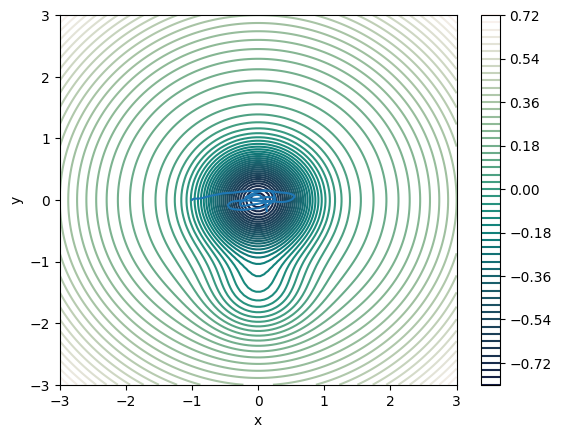

In [110]:
traj = read('md.traj@:')
print(len(traj))
#print(traj)
#print()
# Define an array to store the temperature at each step
temperatures = np.zeros(N_steps+1)

x = np.zeros(N_steps+1)
y = np.zeros(N_steps+1)r = jnp.sqrt(x**2 + y**2)
    large_min = jnp.exp(-0.5*((r)/0.5)**2)

    return scale*(-20*large_min - 5*small_mins + (x**2 +y**2))
z = np.zeros(N_steps+1)

for i,snap in enumerate(traj):
    xyz = snap.get_positions()
    x[i] = xyz[0][0]
    y[i] = xyz[0][1]
    z[i] = xyz[0][2]
    
    # Record the temperature at this step
    temperatures[i] = snap.get_temperature()


plot_2d_bias(f_cvs,trajectory=[x,y],rangeCV1=[-3,3],rangeCV2=[-3,3])

In [ ]:
plt.plot(x)
plt.plot(y)
plt.plot(z)
plt.xlabel('Iterations')
plt.ylabel('x')
plt.savefig('Coordinates_2D_plot.png')

In [ ]:
# Plot the temperature as a function of time
timestep = .5*units.fs
time_ = np.arange(N_steps+1) * timestep / units.fs
plt.plot(time_, temperatures)#/ units.kB)
plt.xlabel('Time (fs)')
plt.ylabel('Temperature (K)')
plt.savefig('NVT_DW_temp.png')
plt.show()
print(np.average(np.array(temperatures)))

# Now we try the Metadynamics code with this

In [ ]:
atoms = Atoms('C',[[-1.0,0.0,0.0]])

jax_calc = Direct_General_Bias_Calculator(f_2D)
atoms.calc = jax_calc 


c = FixedPlane(
    [0],
    [0, 0, 1],
)

atoms.set_constraint(c)


#MaxwellBoltzmannDistribution(atoms, temperature_K=350)
''' the first calc is thrash then but the second one looks great???
Stationary(atoms)  # zero linear momentum
ZeroRotation(atoms)  # zero angular momentum'''
print(atoms.get_velocities())
dyn = Metadynamics(atoms, timestep=.5 * units.fs,bias_height=0, temperature_K=350, friction=.1, trajectory='metad.traj',fixcm=False,cv_function=_cvs_2D,interval_size=10,output_file="flower_meta.txt")#Andersen(atoms, timestep=.5 * units.fs, temperature_K=3000, andersen_prob=0.01,trajectory='md.traj')#

#dyn = VelocityVerlet(atoms, timestep=1.0 * units.fs, trajectory='md.traj')

N_steps = int(1e3)
dyn.run(N_steps) 
dyn_calc= dyn.return_bias()
traj = read('metad.traj@::1')
print(len(traj))

#print(traj)
#print()
x = []
y = np.zeros(N_steps+1)
z = np.zeros(N_steps+1)

# Define an array to store the temperature at each step
temperatures = np.zeros(N_steps+1)
# Define an array to store the energy at each step
energy = np.zeros(N_steps+1)
kin = np.zeros(N_steps+1)
pot = np.zeros(N_steps+1)

for i,snap in enumerate(traj):
    xyz = snap.get_positions()
    x.append(xyz[0][0])
    y[i] = xyz[0][1]
    z[i] = xyz[0][2]
    
    # Record the temperature at this step
    temperatures[i] = snap.get_temperature()
    '''pot[i] = snap.get_potential_energy()
    kin[i] = snap.get_kinetic_energy()
    energy[i] =snap.get_total_energy()'''
    
    

plot_2d_bias(f_cvs,trajectory=[x,y],rangeCV1=[-3,3],rangeCV2=[-3,3],pic_name='Metadyn_flower_well.png')

plt.xlabel('Iterations')
plt.ylabel('x')
plt.plot(x)
plt.plot(y)
plt.plot(z)
#plt.savefig('X_movement_DW_C.png')

In [ ]:
# Plot the temperature as a function of time
timestep = .5*units.fs
time_ = np.arange(N_steps+1) * timestep / units.fs
plt.plot(time_, temperatures)#/ units.kB)
plt.xlabel('Time (fs)')
plt.ylabel('Temperature (K)')
plt.savefig('NVT_DW_temp.png')
plt.show()
print(np.average(np.array(temperatures)))

In [ ]:
# Here now the bias potential should be plotted

atoms = Atoms('C',[[0.0,0.0,0.0]])



Z=[]
x = np.linspace(-3, 3, 100)
y = np.linspace(-3, 3, 100)
X, Y = np.meshgrid(x, y)
CVs=[X,Y]
for j in y:
    for i in x:
        atoms1=copy.deepcopy(atoms)
        pos = atoms.get_positions()
        pos[0][0]+=i
        pos[0][1]+=j
        atoms1.calc = dyn_calc#dyn.return_bias()
        atoms1.set_positions(pos)
         #needs to be an array for the spring method
        Z.append(atoms1.get_potential_energy())
Z=np.array(Z).reshape(100,100)
print(X.shape,Y.shape,len(Z))
plt.xlabel('x')
plt.ylabel('y')
plt.contour(X, Y, Z, 50, cmap='RdGy')
plt.colorbar()
plt.savefig('Biased_2D.png')
plt.show()

In [ ]:
# Here now the bias potential should be plotted

atoms = Atoms('C',[[0.0,0.0,0.0]])



Z=[]
x = np.linspace(-3, 3, 100)
y = np.linspace(-3, 3, 100)
X, Y = np.meshgrid(x, y)
CVs=[X,Y]
for j in y:
    for i in x:
        atoms1=copy.deepcopy(atoms)
        pos = atoms.get_positions()
        pos[0][0]+=i
        pos[0][1]+=j
        atoms1.calc = dyn.return_bias()
        atoms1.set_positions(pos)
         #needs to be an array for the spring method
        Z.append(atoms1.get_potential_energy())
Z=np.array(Z).reshape(100,100)
print(X.shape,Y.shape,len(Z))
plt.xlabel('x')
plt.ylabel('y')
plt.contour(X, Y, Z, 50, cmap='RdGy')
plt.colorbar()
plt.savefig('Biased_2D.png')
plt.show()

In [ ]:
# Here now the biased potential should be plotted

atoms = Atoms('C',[[0.0,0.0,0.0]])



Z=[]
x = np.linspace(-3, 3, 100)
y = np.linspace(-3, 3, 100)
X, Y = np.meshgrid(x, y)
CVs=[X,Y]
for j in y:
    for i in x:
        atoms1=copy.deepcopy(atoms)
        pos = atoms.get_positions()
        pos[0][0]+=i
        pos[0][1]+=j
        atoms1.calc = dyn.return_biased_potential()
        atoms1.set_positions(pos)
         #needs to be an array for the spring method
        Z.append(atoms1.get_potential_energy())
Z=np.array(Z).reshape(100,100)
print(X.shape,Y.shape,len(Z))
plt.xlabel('x')
plt.ylabel('y')
plt.contour(X, Y, Z, 50, cmap='RdGy')
plt.colorbar()
plt.savefig('Biased_2D.png')
plt.show()

# Let's test the WT implementation

In [ ]:


atoms = Atoms('C',[[-1.0,0.0,0.0]])

jax_calc = Direct_General_Bias_Calculator(f_2D)
atoms.calc = jax_calc 


c = FixedPlane(
    [0],
    [0, 0, 1],
)

atoms.set_constraint(c)


MaxwellBoltzmannDistribution(atoms, temperature_K=350)
''' the first calc is thrash then but the second one looks great???
Stationary(atoms)  # zero linear momentum
ZeroRotation(atoms)  # zero angular momentum'''
print(atoms.get_velocities())

dyn = WT_Metadynamics(atoms, timestep=.5*units.fs, temperature_K=350, friction=.1, trajectory='metad.traj',fixcm=False,cv_function=_cvs_2D,
                   std_dev=0.2,bias_height=.01 ,interval_size=10,output_file='test_dimer.txt',well_temp=0.05)

#dyn = VelocityVerlet(atoms, timestep=1.0 * units.fs, trajectory='md.traj')

N_steps = int(1e4)
dyn.run(N_steps) 

traj = read('metad.traj@::1')
print(len(traj))

#print(traj)
#print()
x = []
y = np.zeros(N_steps+1)
z = np.zeros(N_steps+1)

# Define an array to store the temperature at each step
temperatures = np.zeros(N_steps+1)
# Define an array to store the energy at each step
energy = np.zeros(N_steps+1)
kin = np.zeros(N_steps+1)
pot = np.zeros(N_steps+1)

for i,snap in enumerate(traj):
    xyz = snap.get_positions()
    x.append(xyz[0][0])
    y[i] = xyz[0][1]
    z[i] = xyz[0][2]
    
    # Record the temperature at this step
    temperatures[i] = snap.get_temperature()
    '''pot[i] = snap.get_potential_energy()
    kin[i] = snap.get_kinetic_energy()
    energy[i] =snap.get_total_energy()'''
    
    

plot_2d_bias(f_cvs,trajectory=[x,y],rangeCV1=[-3,3],rangeCV2=[-3,3],pic_name='Metadyn_flower_well.png')

plt.xlabel('Iterations')
plt.ylabel('x')
plt.plot(x)
plt.plot(y)
plt.plot(z)
#plt.savefig('X_movement_DW_C.png')

In [ ]:
from ase.build import fcc100, add_adsorbate
from ase.optimize import FIRE,BFGS
from ase.calculators.lammpsrun import LAMMPS

from ase.constraints import FixAtoms,FixedLine

In [ ]:
def _distance(atom_pos):
    return jnp.array([jnp.sqrt(sum((atom_pos[75]-atom_pos[76])**2))])

In [ ]:
initial = fcc100('Pd', size=(5, 5, 3), vacuum=10.0)
dimer = fcc100('Pd', size=(2, 1, 1), vacuum=10.0)
add_adsorbate(initial, dimer, 1.611, position=(4,4))
files = ['Pd_u3.eam']
lammps = LAMMPS(files=files)
lammps.set(pair_style='eam',pair_coeff=['* * Pd_u3.eam'],atom_style='charge',units='metal')
mask = [atom.tag > 2 for atom in initial]
constraint = FixAtoms(mask=mask)
initial.set_constraint(constraint)
initial.calc = lammps

In [ ]:
FIRE(initial).run(fmax=0.05)
constraint = FixedLine([75,76], [1, 0, 0])
initial.set_constraint(constraint)

In [ ]:
"""%%time
MaxwellBoltzmannDistribution(initial, temperature_K=600)
#print(initial.get_velocities())

dyn = Langevin(initial, timestep=1 * units.fs, temperature_K=300, friction=1,trajectory='md.traj',fixcm=False)


N_steps = int(5e3)
dyn.run(N_steps) """

In [ ]:
%%time
timestep = 0.002                    #print(self.position_array)
initial.set_momenta(mom)
dyn = WT_Metadynamics(initial, timestep=timestep, temperature_K=0.05/units.kB, friction=.1, trajectory='metad_dimer.traj',fixcm=False,
                   cvs=_distance,std_dev=0.2,bias_height=.1 ,interval_size=100,output_file='test_dimer.txt',well_temp=0.05)

N_steps = int(50000)
dyn.run(N_steps) 

In [ ]:
atoms1=Trajectory('metad_dimer.traj')[-1]
print(_distance(atoms1.get_positions()))
atoms2=Trajectory('PL_dimer.traj')[-1]
print(_distance(atoms2.get_positions()))

In [ ]:
# Here now the biased potential should be plotted

initial.calc=None


Z=[]
x = np.linspace(-2.5, 10, 1000)

for i in x:
    atoms1=copy.deepcopy(initial)
    pos = initial.get_positions()
    pos[76][0]+=i
    atoms1.calc = dyn.return_bias()
    atoms1.set_positions(pos)
     #needs to be an array for the spring method
    Z.append(atoms1.get_potential_energy())
plt.plot((x +2.6472), Z)
plt.xlabel('d')
plt.ylabel('E')
#plt.savefig('.png')
plt.show()

In [ ]:
traj = read('metad.traj@::1')
print(len(traj))


scm = np.zeros(N_steps+1)
tcm = np.zeros(N_steps+1)

# Define an array to store the temperature at each step
temperatures = np.zeros(N_steps+1)
# Define an array to store the energy at each step
energy = np.zeros(N_steps+1)
kin = np.zeros(N_steps+1)
pot = np.zeros(N_steps+1)

for i,snap in enumerate(traj):
    #print(i)
    #print(snap.calc)
    xyz = snap.get_positions()
    scm[i],tcm[i] =_cvs_moments(xyz,cutoff=1.5)
    # Record the temperature at this step
    temperatures[i] = snap.get_temperature()
    pot[i] = snap.get_potential_energy()
    kin[i] = snap.get_kinetic_energy()
    energy[i] =snap.get_total_energy()
    
# Plot the temperature as a function of time
timestep = .5*units.fs
time_ = np.arange(N_steps+1) * timestep / units.fs
plt.plot(time_, temperatures)#/ units.kB)
plt.xlabel('Time (fs)')
plt.ylabel('Temperature (K)')
plt.savefig('NVT_DW_temp.png')
plt.show()
print(np.average(np.array(temperatures)))


plt.xlabel('Iterations')
plt.ylabel('Energy')
#plt.plot(kin)
plt.plot(pot)
#plt.plot(energy)

In [ ]:
print(np.sqrt(sum((initial.get_positions()[75]-initial.get_positions()[76])**2)))

In [ ]:
import numpy as np
from scipy.stats import moment

def get_coordination_numbers(atoms, cutoff):
    """
    Compute coordination numbers for all atoms in an ASE Atoms object.
    """
    # Get distances between all atoms
    distances = atoms.get_all_distances(mic=True)
    # Get indices of neighboring atoms within the cutoff distance
    indices = np.argwhere(distances <= cutoff)
    # Count number of neighbors for each atom
    coordination_numbers = np.zeros(len(atoms))
    for i in range(len(atoms)):
        coordination_numbers[i] = np.sum(indices[:, 0] == i)
    return coordination_numbers

def get_moments(coordination_numbers):
    """
    Compute the second and third central moments of the distribution of
    coordination numbers.
    """
    scm = moment(coordination_numbers, moment=2)
    tcm = moment(coordination_numbers, moment=3)
    return scm, tcm


In [ ]:
from ase.build import bulk

# Create a simple cubic copper crystal
cu = bulk('Cu', cubic=True)

# Compute coordination numbers
cutoff = 3.0  # Å
cn = get_coordination_numbers(cu, cutoff)

print(cn)
# Compute moments
scm, tcm = get_moments(cn)

print(f"SCM: {scm}")
print(f"TCM: {tcm}")


In [ ]:
import numpy as np
from scipy.stats import moment
from ase import Atoms
from ase.build import molecule
from ase.neighborlist import neighbor_list

def get_coordination_numbers(atoms, cutoff=3.0):
    """Calculate coordination numbers for all atoms in an ASE Atoms object."""
    nl = neighbor_list('ijd', atoms, cutoff)
    return np.bincount(nl[0], minlength=len(atoms))

def get_coordination_moments_numpy(coord_nums):
    """Calculate the second and third central moments of the coordination number distribution using numpy."""
    mean = np.mean(coord_nums)
    scm = np.sum((coord_nums - mean)**2) / len(coord_nums)
    tcm = np.sum((coord_nums - mean)**3) / len(coord_nums)
    return scm, tcm

def get_coordination_moments_scipy(coord_nums):
    """Calculate the second and third central moments of the coordination number distribution using scipy."""
    mean = np.mean(coord_nums)
    scm = moment(coord_nums, moment=2)
    tcm = moment(coord_nums, moment=3)
    return scm, tcm

# Create water molecule
water = molecule('H2O2')
#water.positions += [0.0, 0.0, 2.0]  # shift to avoid periodic boundary effects

# Calculate coordination numbers
coord_nums = get_coordination_numbers(water, cutoff=1.5)

print(coord_nums)
# Calculate moments using numpy
scm_numpy, tcm_numpy = get_coordination_moments_numpy(coord_nums)
print(f"Second central moment (numpy): {scm_numpy:.2f}")
print(f"Third central moment (numpy): {tcm_numpy:.2f}")

# Calculate moments using scipy
scm_scipy, tcm_scipy = get_coordination_moments_scipy(coord_nums)
print(f"Second central moment (scipy): {scm_scipy:.2f}")
print(f"Third central moment (scipy): {tcm_scipy:.2f}")


In [ ]:
def get_coordination_numbers(atoms_positions, cutoff):
    dist_matrix = np.sqrt(np.sum((atoms_positions[:, np.newaxis] - atoms_positions) ** 2, axis=-1))
    return np.sum((dist_matrix <= cutoff) & (dist_matrix > 0), axis=-1)

'''def get_coordination_numbers(atoms_positions, cutoff):
    """Based on the paper"""
    dist_matrix = np.sqrt(np.sum((atoms_positions[:, np.newaxis] - atoms_positions) ** 2, axis=-1))
    print(dist_matrix)
    coordination_numbers = np.zeros(len(atoms_positions), dtype=float)
    print(coordination_numbers)
    for i in range(len(atoms_positions)):
        for j in range(len(atoms_positions)):
            if i != j:
                r_ij = dist_matrix[i, j]
                #print("rij",r_ij)
                x_ij = (1 - (r_ij / cutoff) ** 8) / (1 - (r_ij / cutoff) ** 16)
                #print("xij",x_ij)
                coordination_numbers[i] += x_ij
                #print(coordination_numbers[i])
    return coordination_numbers'''

def get_coordination_numbers(atoms_positions, cutoff):
    dist_matrix = np.sqrt(np.sum((atoms_positions[:, np.newaxis] - atoms_positions) ** 2, axis=-1))
    x_matrix = (1 - (dist_matrix / cutoff) ** 8) / (1 - (dist_matrix / cutoff) ** 16)
    print(x_matrix)
    np.fill_diagonal(x_matrix, 0)  # Set diagonal elements to zero
    coordination_numbers = np.sum(x_matrix, axis=1)
    return coordination_numbers


def get_coordination_moments_numpy(coord_nums):
    """Calculate the second and third central moments of the coordination number distribution using numpy."""
    mean = np.mean(coord_nums)
    scm = np.sum((coord_nums - mean)**2) / len(coord_nums)
    tcm = np.sum((coord_nums - mean)**3) / len(coord_nums)
    return scm, tcm

# Create water molecule
water = molecule('H2O')
#water.positions += [0.0, 0.0, 2.0]  # shift to avoid periodic boundary effects

# Calculate coordination numbers
coord_nums = get_coordination_numbers(water.get_positions(), cutoff=1.5)
print(coord_nums,)
# Calculate moments using numpy
scm_numpy, tcm_numpy = get_coordination_moments_numpy(coord_nums)
print(f"Second central moment (numpy): {scm_numpy:.2f}")
print(f"Third central moment (numpy): {tcm_numpy:.2f}")


# Calculate moments using scipy
scm_scipy, tcm_scipy = get_coordination_moments_scipy(coord_nums)
print(f"Second central moment (scipy): {scm_scipy:.2f}")
print(f"Third central moment (scipy): {tcm_scipy:.2f}")



In [ ]:
import jax
import jax.numpy as jnp
import ase
def fill_diagonal(matrix, value):
    num_rows, num_cols = matrix.shape
    diagonal_indices = jnp.arange(min(num_rows, num_cols))
    filled_matrix = jax.ops.index_update(matrix, (diagonal_indices, diagonal_indices), value)
    return filled_matrix

def _cvs_moments(atoms_positions, cutoff):
    """ Calculate coordination numbers for all atoms in an ASE Atoms object.
        And then calculate the second and third central moments of the coordination number distribution using numpy.
    """
    dist_matrix = jnp.sqrt(jnp.sum((atoms_positions[:, jnp.newaxis] - atoms_positions) ** 2, axis=-1))
    x_matrix = (1 - (dist_matrix / cutoff) ** 8) / (1 - (dist_matrix / cutoff) ** 16)
    #print(x_matrix.shape[0])
    x_matrix = x_matrix.at[jnp.diag_indices(x_matrix.shape[0])].set(0) # there is no jnp.fill_diagonal(x_matrix, 0)  # Set diagonal elements to zero
    coord_nums = jnp.sum(x_matrix, axis=1)
    #print(coord_nums)
    mean = jnp.mean(coord_nums)
    scm = jnp.sum((coord_nums - mean)**2) / len(coord_nums)
    tcm = jnp.sum((coord_nums - mean)**3) / len(coord_nums)
    #print(scm, tcm)
    return scm, tcm

# Create water molecule
water = molecule('H2O')
#water.positions += [0.0, 0.0, 2.0]  # shift to avoid periodic boundary effects


scm_numpy, tcm_numpy = _cvs_moments(water.get_positions(), cutoff=1.0)
print(f"Second central moment (numpy): {scm_numpy:.2f}")
print(f"Third central moment (numpy): {tcm_numpy:.2f}")

atoms = read('isomer.xyz')
cons = [FixedPlane(i, [0, 0, 1]) for i in range(7)]
scm_numpy, tcm_numpy = _cvs_moments(atoms.get_positions(), cutoff=1.5)
print(f"Second central moment (numpy): {scm_numpy:.2f}")
print(f"Third central moment (numpy): {tcm_numpy:.2f}")


In [ ]:
def plot_2d_bias(trajectory=None,pic_name = '2D_plot.png'):
    plt.plot(trajectory[0],trajectory[1])
    plt.xlabel('scm')
    plt.ylabel('tcm')
    plt.savefig(pic_name)
    plt.show()

In [ ]:
cons = [FixedPlane(i, [0, 0, 1]) for i in range(7)]
print(cons)

In [ ]:
from ase import units
from ase.io import read
from ase.constraints import FixedPlane
from ase.calculators.lj import LennardJones

In [ ]:

timestep = 0.005
#.5 * units.fs
atoms = read('isomer.xyz')
print(_cvs_moments(atoms.get_positions(), cutoff=1.5))
print(atoms.get_velocities())
cons = [FixedPlane(i, [0, 0, 1]) for i in range(7)]
atoms.set_constraint(cons)
atoms.set_masses([1, 1, 1, 1, 1, 1, 1])
atoms.calc = LennardJones(rc=2.5, r0=3.0)
'''calc1= LennardJones(rc=2.5, r0=3.0)
calc2 = LennardJones(rc=2.5, r0=3.5)
atoms.calc = LinearCombinationCalculator([calc1,calc2],[0.5,0.5])'''
from functools import partial
dyn = WT_Metadynamics(atoms, timestep=timestep, temperature_K=0.1/units.kB, friction=1, trajectory='metad3.traj'
                      ,fixcm=False,cvs=partial(_cvs_moments, cutoff=1.5),interval_size=500,std_dev=0.1,bias_height=.05,output_file='test3.txt',well_temp=0.1) #Langevin(atoms, timestep=.5 * units.fs, temperature_K=0.1/units.kB, friction=1, trajectory='metad.traj',fixcm=False) #
N_steps = int(1e5)
dyn.run(N_steps) 

In [ ]:
traj = read('metad.traj@::')
print(len(traj))


scm = np.zeros(len(traj))
tcm = np.zeros(len(traj))

# Define an array to store the temperature at each step
temperatures = np.zeros(len(traj))
# Define an array to store the energy at each step
energy = np.zeros(len(traj))
kin = np.zeros(len(traj))
pot = np.zeros(len(traj))

for i,snap in enumerate(traj):
    #print(i)
    #print(snap.calc)
    xyz = snap.get_positions()
    scm[i],tcm[i] =_cvs_moments(xyz,cutoff=1.5)
    # Record the temperature at this step
    temperatures[i] = snap.get_temperature()
    pot[i] = snap.get_potential_energy()
    kin[i] = snap.get_kinetic_energy()
    energy[i] =snap.get_total_energy()
    
plot_2d_bias(trajectory=[scm,tcm],pic_name='Metadyn_biase.png')
plt.xlabel('Iterations')
plt.ylabel('x')
plt.plot(scm)
plt.plot(tcm)
#plt.savefig('X_movement_DW_C.png')

In [ ]:
# Plot the temperature as a function of time
timestep = .5*units.fs
time_ = np.arange(len(traj)) * timestep / units.fs
plt.plot(time_, temperatures)#/ units.kB)
plt.xlabel('Time (fs)')
plt.ylabel('Temperature (K)')
plt.savefig('NVT_DW_temp.png')
plt.show()
print(np.average(np.array(temperatures)))


plt.xlabel('Iterations')
plt.ylabel('Energy')
#plt.plot(kin)
plt.plot(pot)
plt.savefig('E_BIASE_METAD.png')
#plt.plot(energy)

In [ ]:
traj = read('MTD.traj@::10')
print(len(traj))


scm = np.zeros(len(traj))
tcm = np.zeros(len(traj))

# Define an array to store the temperature at each step
temperatures = np.zeros(len(traj))
# Define an array to store the energy at each step
energy = np.zeros(len(traj))
kin = np.zeros(len(traj))
pot = np.zeros(len(traj))

for i,snap in enumerate(traj):
    xyz = snap.get_positions()
    scm[i],tcm[i] =_cvs_moments(xyz,cutoff=1.5)
    # Record the temperature at this step
    temperatures[i] = snap.get_temperature()
    pot[i] = snap.get_potential_energy()
    kin[i] = snap.get_kinetic_energy()
    energy[i] =snap.get_total_energy()
    
plot_2d_bias(trajectory=[scm,tcm],pic_name='PLUMED_METAD.png')
plt.xlabel('Iterations')
plt.ylabel('x')
plt.plot(scm)
plt.plot(tcm)
plt.savefig('PLUMED_METAD_coordinates.png')

In [ ]:
plt.xlabel('Iterations')
plt.ylabel('Energy')
#plt.plot(kin)
#plt.plot(pot)
plt.savefig('E_PLUMED_METAD.png')
plt.plot(energy)

In [ ]:
# Plot the temperature as a function of time
timestep = .5*units.fs
time_ = np.arange(len(traj)) * timestep / units.fs
plt.plot(time_, temperatures)#/ units.kB)
plt.xlabel('Time (fs)')
plt.ylabel('Temperature (K)')

plt.show()

print(np.average(np.array(temperatures)))

In [ ]:
from ase.md.andersen import Andersen
timestep = 0.005
#.5 * units.fs
atoms = read('isomer.xyz')
print(_cvs_moments(atoms.get_positions(), cutoff=1.5))
print(atoms.get_velocities())
cons = [FixedPlane(i, [0, 0, 1]) for i in range(7)]
atoms.set_constraint(cons)
atoms.set_masses([1, 1, 1, 1, 1, 1, 1])
atoms.calc = LennardJones(rc=2.5, r0=3.0)

dyn = Langevin(atoms, timestep, temperature_K=0.1/units.kB, friction=1, trajectory='UnbiasMD.traj',fixcm=False) #Andersen(atoms, timestep, temperature_K=0.1/units.kB, andersen_prob=0.1, trajectory='UnbiasMD.traj',fixcm=False) #
N_steps = int(1000000)
dyn.run(N_steps) 

In [ ]:
traj = Trajectory('UnbiasMD.traj')
print(len(traj))


scm = np.zeros(len(traj))
tcm = np.zeros(len(traj))

# Define an array to store the temperature at each step
temperatures = np.zeros(len(traj))
# Define an array to store the energy at each step
energy = np.zeros(len(traj))
kin = np.zeros(len(traj))
pot = np.zeros(len(traj))

for i,snap in enumerate(traj):
    xyz = snap.get_positions()
    scm[i],tcm[i] =_cvs_moments(xyz,cutoff=1.5)
    # Record the temperature at this step
    temperatures[i] = snap.get_temperature()
    pot[i] = snap.get_potential_energy()
    kin[i] = snap.get_kinetic_energy()
    energy[i] =snap.get_total_energy()
    
    
plot_2d_bias(trajectory=[scm,tcm],pic_name='MD_langevin.png')

plt.xlabel('Iterations')
plt.ylabel('x')
plt.plot(scm)
plt.plot(tcm)
#plt.savefig('X_movement_DW_C.png')

In [ ]:
plt.xlabel('Iterations')
plt.ylabel('Energy')
#plt.plot(kin)
plt.plot(pot)
#plt.plot(energy)
plt.savefig('E_MD_langevin.png')

In [ ]:
from ase.calculators.plumed import Plumed

In [ ]:
timestep = 0.005
ps = 1000 * units.fs

setup = [""]#f"UNITS LENGTH=A TIME={1/ps} ENERGY={units.mol/units.kJ}"]
'''setup = [f"UNITS LENGTH=A TIME={1/ps} ENERGY={units.mol/units.kJ}",
         "COM ATOMS=1-7 LABEL=com",
         "DISTANCE ATOMS=1,com LABEL=d1",
         "UPPER_WALLS ARG=d1 AT=2.0 KAPPA=100.",
         "DISTANCE ATOMS=2,com LABEL=d2",
         "UPPER_WALLS ARG=d2 AT=2.0 KAPPA=100.",
         "DISTANCE ATOMS=3,com LABEL=d3",
         "UPPER_WALLS ARG=d3 AT=2.0 KAPPA=100.",
         "DISTANCE ATOMS=4,com LABEL=d4",
         "UPPER_WALLS ARG=d4 AT=2.0 KAPPA=100.",
         "DISTANCE ATOMS=5,com LABEL=d5",
         "UPPER_WALLS ARG=d5 AT=2.0 KAPPA=100.",
         "DISTANCE ATOMS=6,com LABEL=d6",
         "UPPER_WALLS ARG=d6 AT=2.0 KAPPA=100.",
         "DISTANCE ATOMS=7,com LABEL=d7",
         "UPPER_WALLS ARG=d7 AT=2.0 KAPPA=100.",
         "c1: COORDINATIONNUMBER SPECIES=1-7 MOMENTS=2-3" +
         " SWITCH={RATIONAL R_0=1.5 NN=8 MM=16}",
         "METAD ARG=c1.* HEIGHT=0.05 PACE=500000 " +
         "SIGMA=0.1,0.1 GRID_MIN=-1.5,-1.5 GRID_MAX=2.5,2.5" +
         " GRID_BIN=500,500 BIASFACTOR=5 FILE=HILLS"]'''

atoms = read('isomer.xyz') #read('metad.traj@::10')[200]#
cons = [FixedPlane(i, [0, 0, 1]) for i in range(7)]
atoms.set_constraint(cons)
atoms.set_masses([1, 1, 1, 1, 1, 1, 1])

atoms.calc = Plumed(calc=LennardJones(rc=2.5, r0=3.),
                    input=setup,
                    timestep=timestep,
                    atoms=atoms,)
                    #kT=1.0)

dyn = Andersen(atoms, timestep, temperature_K=0.1/units.kB, andersen_prob=0.1, fixcm=False, trajectory='PLUMED_UnbiasMD.traj')  #Langevin(atoms, timestep, temperature_K=0.1/units.kB, friction=1, fixcm=False, trajectory='PLUMED_UnbiasMD.traj') 
dyn.run(10000)


In [ ]:
traj = read('PLUMED_UnbiasMD.traj@::1')
print(len(traj))


scm = np.zeros(len(traj))
tcm = np.zeros(len(traj))

# Define an array to store the temperature at each step
temperatures = np.zeros(len(traj))
# Define an array to store the energy at each step
energy = np.zeros(len(traj))
kin = np.zeros(len(traj))
pot = np.zeros(len(traj))

for i,snap in enumerate(traj):
    xyz = snap.get_positions()
    scm[i],tcm[i] =_cvs_moments(xyz,cutoff=1.5)
    # Record the temperature at this step
    temperatures[i] = snap.get_temperature()
    pot[i] = snap.get_potential_energy()
    kin[i] = snap.get_kinetic_energy()
    energy[i] =snap.get_total_energy()
    
    
plot_2d_bias(trajectory=[scm,tcm],pic_name='MD_PLUMED.png')

plt.xlabel('Iterations')
plt.ylabel('x')
plt.plot(scm)
plt.plot(tcm)
#plt.savefig('X_movement_DW_C.png')

In [ ]:
plt.xlabel('Iterations')
plt.ylabel('Energy')
#plt.plot(kin)
plt.plot(pot)
#plt.plot(energy)
plt.savefig('E_MD_PLUMED.png')

In [ ]:

timestep = 0.005
ps = 1000 * units.fs

setup = [""]#f"UNITS LENGTH=A TIME={1/ps} ENERGY={units.mol/units.kJ}"]


atoms = read('isomer.xyz') #read('metad.traj@::10')[200]#
cons = [FixedPlane(i, [0, 0, 1]) for i in range(7)]
atoms.set_constraint(cons)
atoms.set_masses([1, 1, 1, 1, 1, 1, 1])

atoms.calc = Plumed(calc=LennardJones(rc=2.5, r0=3.),
                    input=setup,
                    timestep=timestep,
                    atoms=atoms,
                    kT=0.1)

dyn = VelocityVerlet(atoms, timestep=timestep, trajectory='PLUMED_UnbiasMD_const_E.traj')# Langevin(atoms, timestep, temperature_K=0.1/units.kB, friction=1, fixcm=False, trajectory='PLUMED_UnbiasMD.traj')

dyn.run(10000)


In [ ]:
traj = read('PLUMED_UnbiasMD_const_E.traj@::1')
print(len(traj))


scm = np.zeros(len(traj))
tcm = np.zeros(len(traj))

# Define an array to store the temperature at each step
temperatures = np.zeros(len(traj))
# Define an array to store the energy at each step
energy = np.zeros(len(traj))
kin = np.zeros(len(traj))
pot = np.zeros(len(traj))

for i,snap in enumerate(traj):
    xyz = snap.get_positions()
    scm[i],tcm[i] =_cvs_moments(xyz,cutoff=1.5)
    # Record the temperature at this step
    temperatures[i] = snap.get_temperature()
    pot[i] = snap.get_potential_energy()
    kin[i] = snap.get_kinetic_energy()
    energy[i] =snap.get_total_energy()
    
    
plot_2d_bias(trajectory=[scm,tcm],pic_name='MD_PLUMED_const_E.png')

plt.xlabel('Iterations')
plt.ylabel('x')
plt.plot(scm)
plt.plot(tcm)
#plt.savefig('X_movement_DW_C.png')



In [ ]:
plt.xlabel('Iterations')
plt.ylabel('Energy')
#plt.plot(kin)
#plt.plot(pot)
plt.plot(energy)
plt.savefig('E_MD_PLUMED_const_E.png')

In [ ]:

timestep = 0.005
ps = 1000 * units.fs

setup = [""]#f"UNITS LENGTH=A TIME={1/ps} ENERGY={units.mol/units.kJ}"]


atoms = read('isomer.xyz') #read('metad.traj@::10')[200]#
cons = [FixedPlane(i, [0, 0, 1]) for i in range(7)]
atoms.set_constraint(cons)
atoms.set_masses([1, 1, 1, 1, 1, 1, 1])

atoms.calc = LennardJones(rc=2.5, r0=3.)

dyn = VelocityVerlet(atoms, timestep=timestep, trajectory='UnbiasMD_const_E.traj')# Langevin(atoms, timestep, temperature_K=0.1/units.kB, friction=1, fixcm=False, trajectory='PLUMED_UnbiasMD.traj')

dyn.run(10000)


In [ ]:
traj = read('UnbiasMD_const_E.traj@::1')
print(len(traj))


scm = np.zeros(len(traj))
tcm = np.zeros(len(traj))

# Define an array to store the temperature at each step
temperatures = np.zeros(len(traj))
# Define an array to store the energy at each step
energy = np.zeros(len(traj))
kin = np.zeros(len(traj))
pot = np.zeros(len(traj))

for i,snap in enumerate(traj):
    xyz = snap.get_positions()
    scm[i],tcm[i] =_cvs_moments(xyz,cutoff=1.5)
    # Record the temperature at this step
    temperatures[i] = snap.get_temperature()
    pot[i] = snap.get_potential_energy()
    kin[i] = snap.get_kinetic_energy()
    energy[i] =snap.get_total_energy()
    
    
plot_2d_bias(trajectory=[scm,tcm],pic_name='MD_const_E.png')

plt.xlabel('Iterations')
plt.ylabel('x')
plt.plot(scm)
plt.plot(tcm)
#plt.savefig('X_movement_DW_C.png')



In [ ]:
plt.xlabel('Iterations')
plt.ylabel('Energy')
#plt.plot(kin)
#plt.plot(pot)
plt.plot(energy)
plt.savefig('E_MD_const_E.png')

In [ ]:
traj = read('metad.traj@::10')#read('isomer.xyz')
for atoms in traj[:10]:
    atoms.constraints


In [ ]:
timestep = 0.005
ps = 1000 * units.fs


setup = [f"UNITS LENGTH=A TIME={1/ps} ENERGY={units.mol/units.kJ}",
         "COM ATOMS=1-7 LABEL=com",
         "DISTANCE ATOMS=1,com LABEL=d1",
         "UPPER_WALLS ARG=d1 AT=2.0 KAPPA=100.",
         "DISTANCE ATOMS=2,com LABEL=d2",
         "UPPER_WALLS ARG=d2 AT=2.0 KAPPA=100.",
         "DISTANCE ATOMS=3,com LABEL=d3",
         "UPPER_WALLS ARG=d3 AT=2.0 KAPPA=100.",
         "DISTANCE ATOMS=4,com LABEL=d4",
         "UPPER_WALLS ARG=d4 AT=2.0 KAPPA=100.",
         "DISTANCE ATOMS=5,com LABEL=d5",
         "UPPER_WALLS ARG=d5 AT=2.0 KAPPA=100.",
         "DISTANCE ATOMS=6,com LABEL=d6",
         "UPPER_WALLS ARG=d6 AT=2.0 KAPPA=100.",
         "DISTANCE ATOMS=7,com LABEL=d7",
         "UPPER_WALLS ARG=d7 AT=2.0 KAPPA=100.",
         "c1: COORDINATIONNUMBER SPECIES=1-7 MOMENTS=2-3" +
         " SWITCH={RATIONAL R_0=1.5 NN=8 MM=16}",
         "METAD ARG=c1.* HEIGHT=0.05 PACE=500 " +
         "SIGMA=0.1,0.1 GRID_MIN=-1.5,-1.5 GRID_MAX=2.5,2.5" +
         " GRID_BIN=500,500 BIASFACTOR=5 FILE=HILLS"]

atoms = read('metad.traj@::10')[200]#read('isomer.xyz')
cons = [FixedPlane(i, [0, 0, 1]) for i in range(7)]
atoms.set_constraint(cons)
atoms.set_masses([1, 1, 1, 1, 1, 1, 1])

atoms.calc = Plumed(calc=LennardJones(rc=2.5, r0=3.),
                    input=setup,
                    timestep=timestep,
                    atoms=atoms,
                    kT=0.1)

dyn = Langevin(atoms, timestep, temperature_K=0.1/units.kB, friction=1,
               fixcm=False, trajectory='PLUMED_METAD_otherstart.traj')

dyn.run(100000)


In [ ]:
traj = read('PLUMED_METAD_otherstart.traj@::1')
print(len(traj))


scm = np.zeros(len(traj))
tcm = np.zeros(len(traj))

# Define an array to store the temperature at each step
temperatures = np.zeros(len(traj))
# Define an array to store the energy at each step
energy = np.zeros(len(traj))
kin = np.zeros(len(traj))
pot = np.zeros(len(traj))

for i,snap in enumerate(traj):
    xyz = snap.get_positions()
    scm[i],tcm[i] =_cvs_moments(xyz,cutoff=1.5)
    # Record the temperature at this step
    temperatures[i] = snap.get_temperature()
    pot[i] = snap.get_potential_energy()
    kin[i] = snap.get_kinetic_energy()
    energy[i] =snap.get_total_energy()
    
    
plot_2d_bias(trajectory=[scm,tcm],pic_name='MD_PLUMED.png')

plt.xlabel('Iterations')
plt.ylabel('x')
plt.plot(scm)
plt.plot(tcm)
#plt.savefig('X_movement_DW_C.png')

In [ ]:
plt.xlabel('Iterations')
plt.ylabel('Energy')
#plt.plot(kin)
#plt.plot(pot)
plt.plot(energy)
plt.savefig('E_METAD_PLUMED_otherstart.png')

In [ ]:
traj = read('MTD_wo_wt.traj@::')
print(len(traj))


scm = np.zeros(len(traj))
tcm = np.zeros(len(traj))

# Define an array to store the temperature at each step
temperatures = np.zeros(len(traj))
# Define an array to store the energy at each step
energy = np.zeros(len(traj))
kin = np.zeros(len(traj))
pot = np.zeros(len(traj))

for i,snap in enumerate(traj):
    xyz = snap.get_positions()
    scm[i],tcm[i] =_cvs_moments(xyz,cutoff=1.5)
    # Record the temperature at this step
    temperatures[i] = snap.get_temperature()
    pot[i] = snap.get_potential_energy()
    kin[i] = snap.get_kinetic_energy()
    energy[i] =snap.get_total_energy()
    
plot_2d_bias(trajectory=[scm,tcm],pic_name='PLUMED_METAD_wo_wt.png')
plt.xlabel('Iterations')
plt.ylabel('x')
plt.plot(scm)
plt.plot(tcm)
#plt.savefig('PLUMED_METAD_coordinates.png')

In [ ]:
plt.xlabel('Iterations')
plt.ylabel('Energy')
#plt.plot(kin)
#plt.plot(pot)
plt.plot(energy)
plt.savefig('E_METAD_wo_wt_PLUMED.png')

In [ ]:
### let's compare some energies

atoms = read('UnbiasMD.traj@::1')[1471]
setup = []
atoms.calc = LennardJones(rc=2.5, r0=3.0)
print(f'Energy based on the ASE LJ: {atoms.get_potential_energy()}')
print(f'Force based on the ASE LJ: {atoms.get_forces()}')

atoms.calc = Plumed(calc=LennardJones(rc=2.5, r0=3.),
                    input=setup,
                    timestep=timestep,
                    atoms=atoms,
                    kT=0.1)
print(f'Energy based on the PLUMED LJ: {atoms.get_potential_energy()}')
print(f'Force based on the PLUMED LJ: {atoms.get_forces()}')

import matplotlib.pyplot as plt
from ase.visualize.plot import plot_atoms
from ase.io import Trajectory
from ase.lattice.cubic import FaceCenteredCubic


fig,ax= plt.subplots(1,figsize=(7, 7))
plot_atoms(atoms, ax,radii=0.9)
plt.axis('off')
fig.savefig(f"low_E_example.png",transparent=True)


In [ ]:
atoms = read('MTD.traj@::100')[101]
atoms.calc = LennardJones(rc=2.5, r0=3.0)
print(f'Energy based on the ASE LJ: {atoms.get_potential_energy()}')
print(f'Force based on the ASE LJ: {atoms.get_forces()}')


atoms.calc = Plumed(calc=LennardJones(rc=2.5, r0=3.),
                    input=setup,
                    timestep=timestep,
                    atoms=atoms,
                    kT=0.1)
print(f'Energy based on the PLUMED LJ: {atoms.get_potential_energy()}')
print(f'Force based on the PLUMED LJ: {atoms.get_forces()}')

In [ ]:
conda install -c conda-forge asap3

In [ ]:
"""Demonstrates molecular dynamics with constant temperature."""
from ase.lattice.cubic import FaceCenteredCubic
from ase.md.langevin import Langevin
from ase.io.trajectory import Trajectory
from ase import units

from asap3 import EMT  # Way too slow with ase.EMT !
size = 5

T = 1500  # Kelvin

# Set up a crystal
atoms = FaceCenteredCubic(directions=[[1, 0, 0], [0, 1, 0], [0, 0, 1]],
                          symbol="Cu",
                          size=(size, size, size),
                          pbc=False)

# Describe the interatomic interactions with the Effective Medium Theory
atoms.calc = EMT()

# We want to run MD with constant energy using the Langevin algorithm
# with a time step of 5 fs, the temperature T and the friction
# coefficient to 0.02 atomic units.
dyn = Langevin(atoms, 5 * units.fs, T * units.kB, 0.002, trajectory="moldyn3.traj")


def printenergy(a=atoms):  # store a reference to atoms in the definition.
    """Function to print the potential, kinetic and total energy."""
    epot = a.get_potential_energy() / len(a)
    ekin = a.get_kinetic_energy() / len(a)
    print('Energy per atom: Epot = %.3feV  Ekin = %.3feV (T=%3.0fK)  '
          'Etot = %.3feV' % (epot, ekin, ekin / (1.5 * units.kB), epot + ekin))


dyn.attach(printenergy, interval=500)



# Now run the dynamics
dyn.run(1e5)

In [ ]:
atoms.calc =EMT()
# Describe the interatomic interactions with the Effective Medium Theory
'''atoms.calc = Plumed(calc=EMT(),
                    input=setup,
                    timestep=0.005,
                    atoms=atoms,
                    kT=T * units.kB)'''

atoms.get_potential_energy()
emt =LennardJones(rc =2,r0=2)
emt.get_potential_energy(atoms)

In [ ]:
"""Demonstrates molecular dynamics with constant temperature."""
from ase.lattice.cubic import FaceCenteredCubic
from ase.md.langevin import Langevin
from ase.io.trajectory import Trajectory
from ase import units
#from ase.calculators.emt import EMT
from asap3 import EMT  # Way too slow with ase.EMT !
size = 4
setup = ['']
T = 1500  # Kelvin

# Set up a crystal
atoms = FaceCenteredCubic(directions=[[1, 0, 0], [0, 1, 0], [0, 0, 1]],
                          symbol="Cu",
                          size=(size, size, size),
                          pbc=False)

# Describe the interatomic interactions with the Effective Medium Theory
atoms.calc = Plumed(calc=EMT(),
                    input=setup,
                    timestep=0.005,
                    atoms=atoms,
                    kT=T * units.kB)

# We want to run MD with constant energy using the Langevin algorithm
# with a time step of 5 fs, the temperature T and the friction
# coefficient to 0.02 atomic units.
dyn = Langevin(atoms, 5 * units.fs, T * units.kB, 0.002, trajectory="moldyn3_plumed.traj")


def printenergy(a=atoms):  # store a reference to atoms in the definition.
    """Function to print the potential, kinetic and total energy."""
    epot = a.get_potential_energy() / len(a)
    ekin = a.get_kinetic_energy() / len(a)
    print('Energy per atom: Epot = %.3feV  Ekin = %.3feV (T=%3.0fK)  '
          'Etot = %.3feV' % (epot, ekin, ekin / (1.5 * units.kB), epot + ekin))


dyn.attach(printenergy, interval=500)



# Now run the dynamics
dyn.run(1e5)

In [ ]:
def bias_gaussian_2D(cvs,mean_cvs,std_dev,bias_height,regu):
        """
        Evaluate a 2D Gaussian potential energy surface for the given input collective variable(s) (cvs).

        Args:
            cvs (float or numpy array): Input value(s) for evaluating the 2D Gaussian.

        Returns:
            float or numpy array: Value(s) of the 2D Gaussian at the given input(s), summed over all means.
        """
        x, y = cvs
        
        #print(mean_cvs[:, 0])
        # Evaluate the Gaussian for all means at once using numpy broadcasting
        gaussian_vals = jnp.exp(-0.5*((x - mean_cvs[:, 0])**2/(0.5*std_dev**2)) \
                                                      - 0.5*((y - mean_cvs[:, 1])**2/(0.5*std_dev**2)))
        return bias_height*jnp.sum(gaussian_vals*regu,axis=0)[0] 

In [ ]:
traj = read('metad3.traj@::500')
print(len(traj))

cvs_cm = np.zeros([len(traj),2])
scm = np.zeros(len(traj))
tcm = np.zeros(len(traj))


for i,snap in enumerate(traj):
    #print(i)
    #print(snap.calc)
    xyz = snap.get_positions()
    scm[i],tcm[i] =_cvs_moments(xyz,cutoff=1.5)
    cvs_cm[i]= [scm[i],tcm[i]]

In [ ]:
print(scm,tcm)

In [ ]:
print(cvs_cm)

In [ ]:
cvs_cm,reg=dyn.return_func()

In [ ]:
x = np.linspace(-0, 1.5, 100)

y = np.linspace(-1, 1.5, 100)


In [ ]:
list_of_e =np.zeros((len(x), len(y)))
for j, yj in enumerate(y):    
    for i, xi in enumerate(x):
        #print(x,y)
        list_of_e[j, i] = bias_gaussian_2D(cvs = np.array([xi,yj]),mean_cvs=cvs_cm,std_dev=0.1,bias_height =0.05,regu=reg)


In [ ]:
print(list_of_e)

In [ ]:
plt.xlabel('scm')
plt.ylabel('tcm')
plt.contour(x, y, list_of_e, 50, cmap=cmo.tempo_r)
plt.colorbar()
plt.savefig('Biased_2D.png')
plt.show()

In [ ]:
traj = read('metad.traj@::500')
scm = np.zeros(len(traj))
tcm = np.zeros(len(traj))


for i,snap in enumerate(traj):
    xyz = snap.get_positions()
    scm[i],tcm[i] =_cvs_moments(xyz,cutoff=1.5)

In [ ]:
time = np.linspace(0,1000,1001)/2
print(time)
len(scm)
height = [0.1 for i in range(1001)]

In [ ]:
header1 = "Header Line 1"
header2 = "Header Line 2"
header3 = "Header Line 3"

list1 = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
list2 = [11, 12, 13, 14, 15, 16, 17, 18, 19, 20]
list3 = [21, 22, 23, 24, 25, 26, 27, 28, 29, 30]
list4 = [31, 32, 33, 34, 35, 36, 37, 38, 39, 40]

# Create the content for the file
content = f"{header1}\n{header2}\n{header3}\n"
content += "List1\tList2\tList3\tList4\n"

for i in range(10):
    content += f"{list1[i]}\t{list2[i]}\t{list3[i]}\t{list4[i]}\n"

# Save the content to a .txt file
filename = "table_data.txt"
with open(filename, "w") as file:
    file.write(content)

print(f"The file '{filename}' has been created.")
